# Notebook 1b — Ground Truth Spectral Sampling


**Goal:** Extract real Sentinel-2 band values at known locations,  
derive Nouakchott-specific thresholds from actual data, not literature.

---

## Cell 1 — Setup & Ground Truth Points
Verify the points look correct on the printed table.

In [1]:
import ee
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

ee.Initialize(project=os.environ.get('GEE_PROJECT'))
print('✓ GEE initialized')

# ── Ground truth points (from Google Earth) ─────────────────
# Each point is a location we KNOW the land cover type
GROUND_TRUTH = {
    'Urban 1'   : {'lat':  18.093214, 'lon': -15.980358, 'type': 'urban'},
    'Urban 2'   : {'lat':  18.081911, 'lon': -15.977133, 'type': 'urban'},
    'Sand 1'    : {'lat':  18.026425, 'lon': -16.010217, 'type': 'sand'},
    'Sand 2'    : {'lat':  18.198997, 'lon': -15.957258, 'type': 'sand'},
    'Lagoon'    : {'lat':  18.043989, 'lon': -15.980083, 'type': 'water'},
    'Major Road': {'lat':  18.087844, 'lon': -15.980406, 'type': 'road'},
}

# Print summary
print(f'\n{"Point":12s} {"Type":10s} {"Lat":12s} {"Lon":12s}')
print('-' * 50)
for name, info in GROUND_TRUTH.items():
    print(f"{name:12s} {info['type']:10s} {info['lat']:12.6f} {info['lon']:12.6f}")

print('\n→ Next cell: build Sentinel-2 composite')

✓ GEE initialized

Point        Type       Lat          Lon         
--------------------------------------------------
Urban 1      urban         18.093214   -15.980358
Urban 2      urban         18.081911   -15.977133
Sand 1       sand          18.026425   -16.010217
Sand 2       sand          18.198997   -15.957258
Lagoon       water         18.043989   -15.980083
Major Road   road          18.087844   -15.980406

→ Next cell: build Sentinel-2 composite


## Cell 2 — Build Sentinel-2 Composite
Using a 6-month dry season window (Oct 2023 → Mar 2024) for maximum clean pixels.

In [2]:
# ── Build composite over Nouakchott ─────────────────────────
# Bounding box around our 6 points with buffer
lats = [v['lat'] for v in GROUND_TRUTH.values()]
lons = [v['lon'] for v in GROUND_TRUTH.values()]
buf  = 0.05  # degrees

region = ee.Geometry.Rectangle([
    min(lons) - buf, min(lats) - buf,
    max(lons) + buf, max(lats) + buf
])

def mask_clouds(img):
    scl = img.select('SCL')
    ok  = (scl.neq(3).And(scl.neq(8)).And(scl.neq(9))
              .And(scl.neq(10)).And(scl.neq(11)))
    return (img.updateMask(ok)
               .divide(10000)
               .copyProperties(img, ['system:time_start']))

collection = (
    ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
    .filterDate('2023-10-01', '2024-04-01')   # 6-month dry season window
    .filterBounds(region)
    .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20))
    .map(mask_clouds)
)

n_images  = collection.size().getInfo()
composite = collection.median()

print(f'✓ Composite built from {n_images} images')
print(f'  Date range: Oct 2023 → Apr 2024')
print(f'  More images = more stable median = more reliable values')
print('\n→ Next cell: extract band values at each point')

✓ Composite built from 90 images
  Date range: Oct 2023 → Apr 2024
  More images = more stable median = more reliable values

→ Next cell: extract band values at each point


## Cell 3 — Extract Raw Band Values
Sample every Sentinel-2 band at each known point.

**What to look for in the output:**
- Urban vs Sand: should differ most in B11 (SWIR1) and B12 (SWIR2)
- Water/Lagoon: very low in all SWIR bands, higher in Blue/Green
- Road: similar to urban but often brighter in all bands

In [3]:
BANDS = ['B2','B3','B4','B8','B11','B12']
BAND_NAMES = {
    'B2' : 'Blue  (490nm)',
    'B3' : 'Green (560nm)',
    'B4' : 'Red   (665nm)',
    'B8' : 'NIR   (842nm)',
    'B11': 'SWIR1 (1610nm)',
    'B12': 'SWIR2 (2190nm)',
}

TYPE_COLORS = {
    'urban': '#d62728',
    'sand' : '#f4a261',
    'water': '#1f77b4',
    'road' : '#7f7f7f',
}

# ── Sample each point ────────────────────────────────────────
records = []
for name, info in GROUND_TRUTH.items():
    point = ee.Geometry.Point([info['lon'], info['lat']])

    # Sample using a small 30m buffer (3x3 pixel window)
    # More robust than single pixel (avoids sub-pixel location errors)
    values = composite.select(BANDS).reduceRegion(
        reducer  = ee.Reducer.mean(),
        geometry = point.buffer(30),
        scale    = 10,
        maxPixels= 1e6
    ).getInfo()

    row = {'point': name, 'type': info['type']}
    row.update(values)
    records.append(row)
    print(f'  ✓ {name:12s} ({info["type"]:6s}): B4={values.get("B4","N/A"):.4f}  '
          f'B8={values.get("B8","N/A"):.4f}  '
          f'B11={values.get("B11","N/A"):.4f}  '
          f'B12={values.get("B12","N/A"):.4f}')

df = pd.DataFrame(records).set_index('point')

# Round for readability
for b in BANDS:
    if b in df.columns:
        df[b] = df[b].round(4)

print('\n── Full Band Values Table ────────────────────────────────────')
print(f'{"":15s}', end='')
for b in BANDS:
    print(f'{BAND_NAMES[b]:>16s}', end='')
print()
print('-' * (15 + 16*len(BANDS)))
for name, row in df.iterrows():
    print(f'{name:15s}', end='')
    for b in BANDS:
        v = row.get(b, float('nan'))
        print(f'{v:>16.4f}', end='')
    print(f'  [{row["type"]}]')

print('\n→ Next cell: compute ratios and see where types separate')

  ✓ Urban 1      (urban ): B4=0.2421  B8=0.3254  B11=0.3519  B12=0.3195
  ✓ Urban 2      (urban ): B4=0.2653  B8=0.3007  B11=0.3549  B12=0.3450
  ✓ Sand 1       (sand  ): B4=0.2917  B8=0.3486  B11=0.4378  B12=0.3858
  ✓ Sand 2       (sand  ): B4=0.4989  B8=0.6025  B11=0.7303  B12=0.6848
  ✓ Lagoon       (water ): B4=0.1644  B8=0.2141  B11=0.1495  B12=0.1244
  ✓ Major Road   (road  ): B4=0.1904  B8=0.2247  B11=0.2710  B12=0.2427

── Full Band Values Table ────────────────────────────────────
                  Blue  (490nm)   Green (560nm)   Red   (665nm)   NIR   (842nm)  SWIR1 (1610nm)  SWIR2 (2190nm)
---------------------------------------------------------------------------------------------------------------
Urban 1                  0.1429          0.1950          0.2421          0.3254          0.3519          0.3195  [urban]
Urban 2                  0.1630          0.2144          0.2653          0.3007          0.3549          0.3450  [urban]
Sand 1                   0.1326       

## Cell 4 — Compute Index Values at Each Point
Now we compute every index for these known points.

**This tells us the actual index range for each land cover type in Nouakchott.**
We derive thresholds FROM this data.

In [4]:
eps = 1e-10

def compute_point_indices(row):
    b2  = row['B2']
    b3  = row['B3']
    b4  = row['B4']
    b8  = row['B8']
    b11 = row['B11']
    b12 = row['B12']

    ndvi       = (b8  - b4)  / (b8  + b4  + eps)
    ndbi       = (b11 - b8)  / (b11 + b8  + eps)
    ndwi       = (b3  - b8)  / (b3  + b8  + eps)
    bu         = ndbi - ndvi
    baei       = (b4 + 0.3)  / (b3  + b11 + eps)
    swir_ratio = b12 / (b11 + eps)   # sand detector
    ndbai      = (b11 - b3)  / (b11 + b3  + eps)   # built-up vs soil

    return pd.Series({
        'NDVI'      : round(ndvi, 4),
        'NDBI'      : round(ndbi, 4),
        'NDWI'      : round(ndwi, 4),
        'BU'        : round(bu,   4),
        'BAEI'      : round(baei, 4),
        'SWIR2/SWIR1': round(swir_ratio, 4),
        'NDBAI'     : round(ndbai, 4),
    })

idx_df = df.apply(compute_point_indices, axis=1)
idx_df.insert(0, 'type', df['type'])

print('── Index Values at Known Locations ───────────────────────────────────────')
print(idx_df.to_string())

print()
print('── What to look for ──────────────────────────────────────────────────────')
print('  NDBI   : urban > sand ?  (should be, but might not be in Saharan cities)')
print('  NDWI   : water >> urban ?  (should be very negative for dry land)')
print('  SWIR2/SWIR1: sand ≈ 1.0 ?  urban < 0.95 ?  (key sand discriminator)')
print('  NDBAI  : built-up >> sand ?  (alternative index for arid zones)')
print()
print('→ Next cell: spectral profile plot')

── Index Values at Known Locations ───────────────────────────────────────
             type    NDVI    NDBI    NDWI      BU    BAEI  SWIR2/SWIR1   NDBAI
point                                                                         
Urban 1     urban  0.1468  0.0391 -0.2506 -0.1077  0.9912       0.9079  0.2869
Urban 2     urban  0.0625  0.0827 -0.1675  0.0201  0.9930       0.9721  0.2468
Sand 1       sand  0.0889  0.1134 -0.2697  0.0246  0.9270       0.8812  0.3718
Sand 2       sand  0.0941  0.0959 -0.2963  0.0018  0.7555       0.9377  0.3813
Lagoon      water  0.1313 -0.1777 -0.1607 -0.3090  1.5261       0.8321 -0.0174
Major Road   road  0.0826  0.0934 -0.1842  0.0108  1.1517       0.8956  0.2729

── What to look for ──────────────────────────────────────────────────────
  NDBI   : urban > sand ?  (should be, but might not be in Saharan cities)
  NDWI   : water >> urban ?  (should be very negative for dry land)
  SWIR2/SWIR1: sand ≈ 1.0 ?  urban < 0.95 ?  (key sand discriminator)
  ND

## Cell 5 — Spectral Profile Plot
Visual comparison of band values across land cover types.

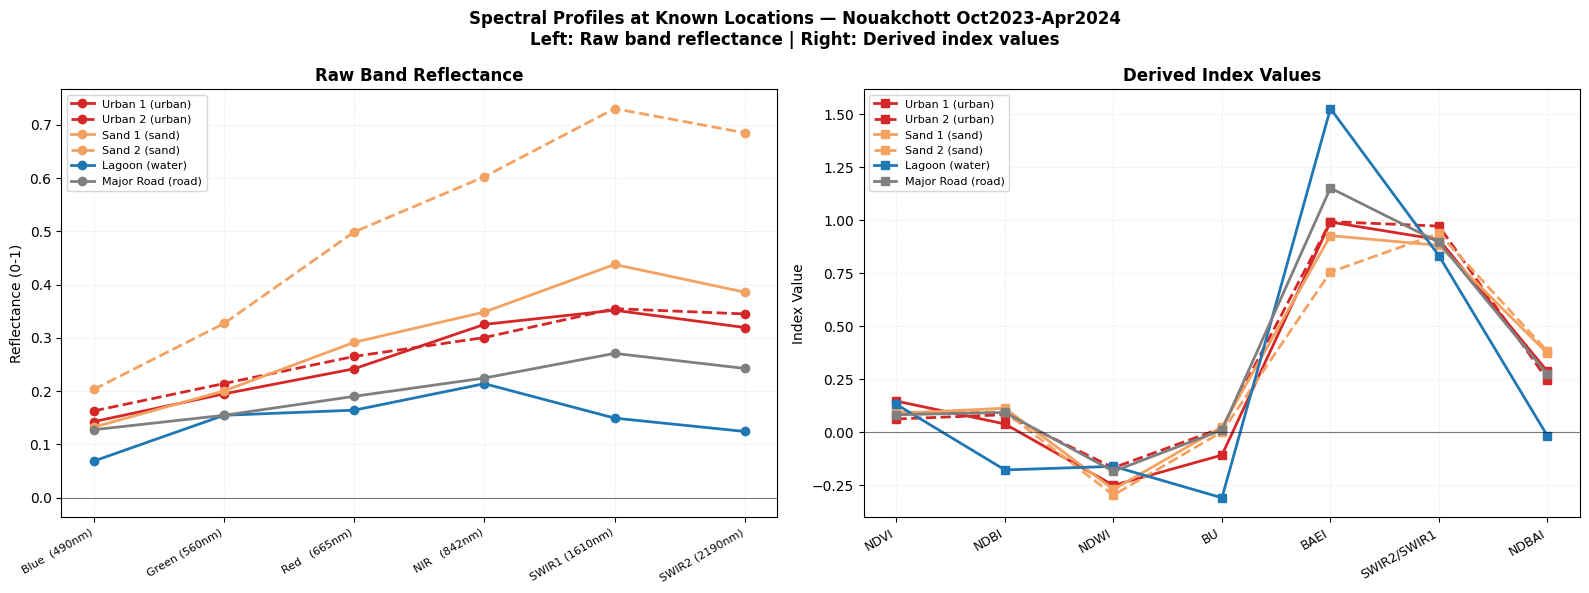


→ Look at the plot and answer:
  1. Is Urban clearly separated from Sand in any index?
  2. Which index shows the biggest Urban vs Sand gap?
  3. Is SWIR2/SWIR1 working as sand discriminator (sand ≈ 1.0)?
  4. What NDBI value do the urban points actually have?

→ Share the plot + the index table and we derive thresholds from there.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Spectral Profiles at Known Locations — Nouakchott Oct2023-Apr2024\n'
             'Left: Raw band reflectance | Right: Derived index values',
             fontsize=12, fontweight='bold')

band_labels  = [BAND_NAMES[b] for b in BANDS]
band_x       = list(range(len(BANDS)))
index_labels = ['NDVI','NDBI','NDWI','BU','BAEI','SWIR2/SWIR1','NDBAI']
index_x      = list(range(len(index_labels)))

# ── Left: raw reflectance ────────────────────────────────────
ax = axes[0]
for name, row in df.iterrows():
    color  = TYPE_COLORS[row['type']]
    values = [row[b] for b in BANDS]
    ls     = '-' if '1' in name or name in ['Lagoon','Major Road'] else '--'
    ax.plot(band_x, values, color=color, lw=2, ls=ls,
            marker='o', ms=6, label=f"{name} ({row['type']})")

ax.set_xticks(band_x)
ax.set_xticklabels(band_labels, rotation=30, ha='right', fontsize=8)
ax.set_ylabel('Reflectance (0-1)')
ax.set_title('Raw Band Reflectance', fontweight='bold')
ax.legend(fontsize=8, loc='upper left')
ax.grid(alpha=0.3, ls=':')
ax.axhline(0, color='black', lw=0.8, alpha=0.5)

# ── Right: index values ──────────────────────────────────────
ax = axes[1]
for name, row in idx_df.iterrows():
    color  = TYPE_COLORS[row['type']]
    values = [row[i] for i in index_labels]
    ls     = '-' if '1' in name or name in ['Lagoon','Major Road'] else '--'
    ax.plot(index_x, values, color=color, lw=2, ls=ls,
            marker='s', ms=6, label=f"{name} ({row['type']})")

ax.set_xticks(index_x)
ax.set_xticklabels(index_labels, rotation=30, ha='right', fontsize=9)
ax.set_ylabel('Index Value')
ax.set_title('Derived Index Values', fontweight='bold')
ax.legend(fontsize=8, loc='upper left')
ax.grid(alpha=0.3, ls=':')
ax.axhline(0, color='black', lw=0.8, alpha=0.5)

plt.tight_layout()
plt.savefig('/outputs/gt_01_spectral_profiles.png', dpi=150, bbox_inches='tight')
plt.show()

print('\n→ Look at the plot and answer:')
print('  1. Is Urban clearly separated from Sand in any index?')
print('  2. Which index shows the biggest Urban vs Sand gap?')
print('  3. Is SWIR2/SWIR1 working as sand discriminator (sand ≈ 1.0)?')
print('  4. What NDBI value do the urban points actually have?')
print()
print('→ Share the plot + the index table and we derive thresholds from there.')

In [6]:
# CELL 6 — Build Two Temporal Composites
import ee
import geopandas as gpd
import shapely.ops
import json as _json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from io import BytesIO
from PIL import Image
import os

ee.Initialize(project=os.environ.get('GEE_PROJECT'))

# Reload boundaries with new shapefile
gdf_all = gpd.read_file('/data/polygons/mrt_admbnda_adm2_gov_20200801.shp')
if gdf_all.crs.to_epsg() != 4326:
    gdf_all = gdf_all.to_crs(epsg=4326)
gdf    = gdf_all[gdf_all['ADM1_EN'] == 'Nouakchott'].copy().reset_index(drop=True)
bounds = gdf.total_bounds
union  = shapely.ops.unary_union(gdf.geometry)
gj     = _json.loads(gpd.GeoSeries([union], crs='EPSG:4326').to_json())
region_ee = ee.Geometry(gj['features'][0]['geometry'])
print(f'Boundaries: {len(gdf)} moughataas')

# Ground truth points (from previous cells)
GROUND_TRUTH = {
    'Urban 1'   : {'lat':  18.093214, 'lon': -15.980358, 'type': 'urban'},
    'Urban 2'   : {'lat':  18.081911, 'lon': -15.977133, 'type': 'urban'},
    'Sand 1'    : {'lat':  18.026425, 'lon': -16.010217, 'type': 'sand'},
    'Sand 2'    : {'lat':  18.198997, 'lon': -15.957258, 'type': 'sand'},
    'Lagoon'    : {'lat':  18.043989, 'lon': -15.980083, 'type': 'water'},
    'Major Road': {'lat':  18.087844, 'lon': -15.980406, 'type': 'road'},
}

TYPE_COLORS = {
    'urban': '#d62728',
    'sand' : '#f4a261',
    'water': '#1f77b4',
    'road' : '#7f7f7f',
}

def build_composite(date_start, date_end, region):
    def mask(img):
        scl = img.select('SCL')
        ok  = (scl.neq(3).And(scl.neq(8)).And(scl.neq(9))
                  .And(scl.neq(10)).And(scl.neq(11)))
        b1  = img.select('B1').toFloat()
        b2  = img.select('B2').toFloat()
        dust_ok = b1.divide(b2.add(1e-6)).lt(0.90)
        return (img.updateMask(ok.And(dust_ok))
                   .divide(10000)
                   .copyProperties(img, ['system:time_start']))
    col = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
             .filterDate(date_start, date_end)
             .filterBounds(region)
             .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 30))
             .map(mask))
    n = col.size().getInfo()
    print(f'  {date_start} to {date_end}: {n} images')
    return col.median(), n

print('Building composites...')
comp_before, n1 = build_composite('2015-10-01', '2016-04-01', region_ee)
comp_after,  n2 = build_composite('2023-10-01', '2024-04-01', region_ee)
print(f'\nBefore: {n1} images | After: {n2} images')
print('Next: run Cell 7')

Boundaries: 9 moughataas
Building composites...
  2015-10-01 to 2016-04-01: 8 images
  2023-10-01 to 2024-04-01: 96 images

Before: 8 images | After: 96 images
Next: run Cell 7


In [7]:
# CELL 7 — Validate Change Direction at Known Points
BANDS_CHANGE = ['B4', 'B8', 'B11', 'B12']

records_change = []
for name, info in GROUND_TRUTH.items():
    point = ee.Geometry.Point([info['lon'], info['lat']])
    buf30 = point.buffer(30)

    v_before = comp_before.select(BANDS_CHANGE).reduceRegion(
        reducer=ee.Reducer.mean(), geometry=buf30,
        scale=10, maxPixels=1e6
    ).getInfo()

    v_after = comp_after.select(BANDS_CHANGE).reduceRegion(
        reducer=ee.Reducer.mean(), geometry=buf30,
        scale=10, maxPixels=1e6
    ).getInfo()

    row = {'point': name, 'type': info['type']}
    for b in BANDS_CHANGE:
        bef = v_before.get(b)
        aft = v_after.get(b)
        bef = float(bef) if bef is not None else np.nan
        aft = float(aft) if aft  is not None else np.nan
        row[f'{b}_before'] = round(bef, 4)
        row[f'{b}_after']  = round(aft, 4)
        row[f'{b}_delta']  = round(aft - bef, 4) if not (np.isnan(bef) or np.isnan(aft)) else np.nan
    records_change.append(row)

df_chg = pd.DataFrame(records_change).set_index('point')

print('Change at Known Points (delta = after minus before)')
print(f'{"Point":12s} {"Type":6s} {"B11_before":>11s} {"B11_after":>10s} {"B11_delta":>10s}  {"B8_delta":>9s}  {"B4_delta":>9s}  Interpretation')
print('-' * 90)
for name, row in df_chg.iterrows():
    d = row['B11_delta']
    if   d < -0.02: flag = 'new construction?'
    elif d >  0.02: flag = 'sand expansion?'
    else:           flag = 'stable'
    print(f'{name:12s} {row["type"]:6s} '
          f'{row["B11_before"]:>11.4f} {row["B11_after"]:>10.4f} '
          f'{row["B11_delta"]:>10.4f}  {row["B8_delta"]:>9.4f}  {row["B4_delta"]:>9.4f}  {flag}')

print()
print('Expected: urban B11_delta negative | sand B11_delta near zero or positive')

Change at Known Points (delta = after minus before)
Point        Type    B11_before  B11_after  B11_delta   B8_delta   B4_delta  Interpretation
------------------------------------------------------------------------------------------
Urban 1      urban       0.3771     0.3591    -0.0180    -0.0241    -0.0271  stable
Urban 2      urban       0.3358     0.3581     0.0223     0.0142     0.0012  sand expansion?
Sand 1       sand        0.4732     0.4331    -0.0400    -0.0541    -0.0564  new construction?
Sand 2       sand        0.7134     0.7303     0.0169     0.0053     0.0107  stable
Lagoon       water       0.1696     0.2302     0.0606     0.0537    -0.0124  sand expansion?
Major Road   road        0.3030     0.2817    -0.0213    -0.0465    -0.0647  new construction?

Expected: urban B11_delta negative | sand B11_delta near zero or positive


Fetching thumbnails...
Done. Plotting...


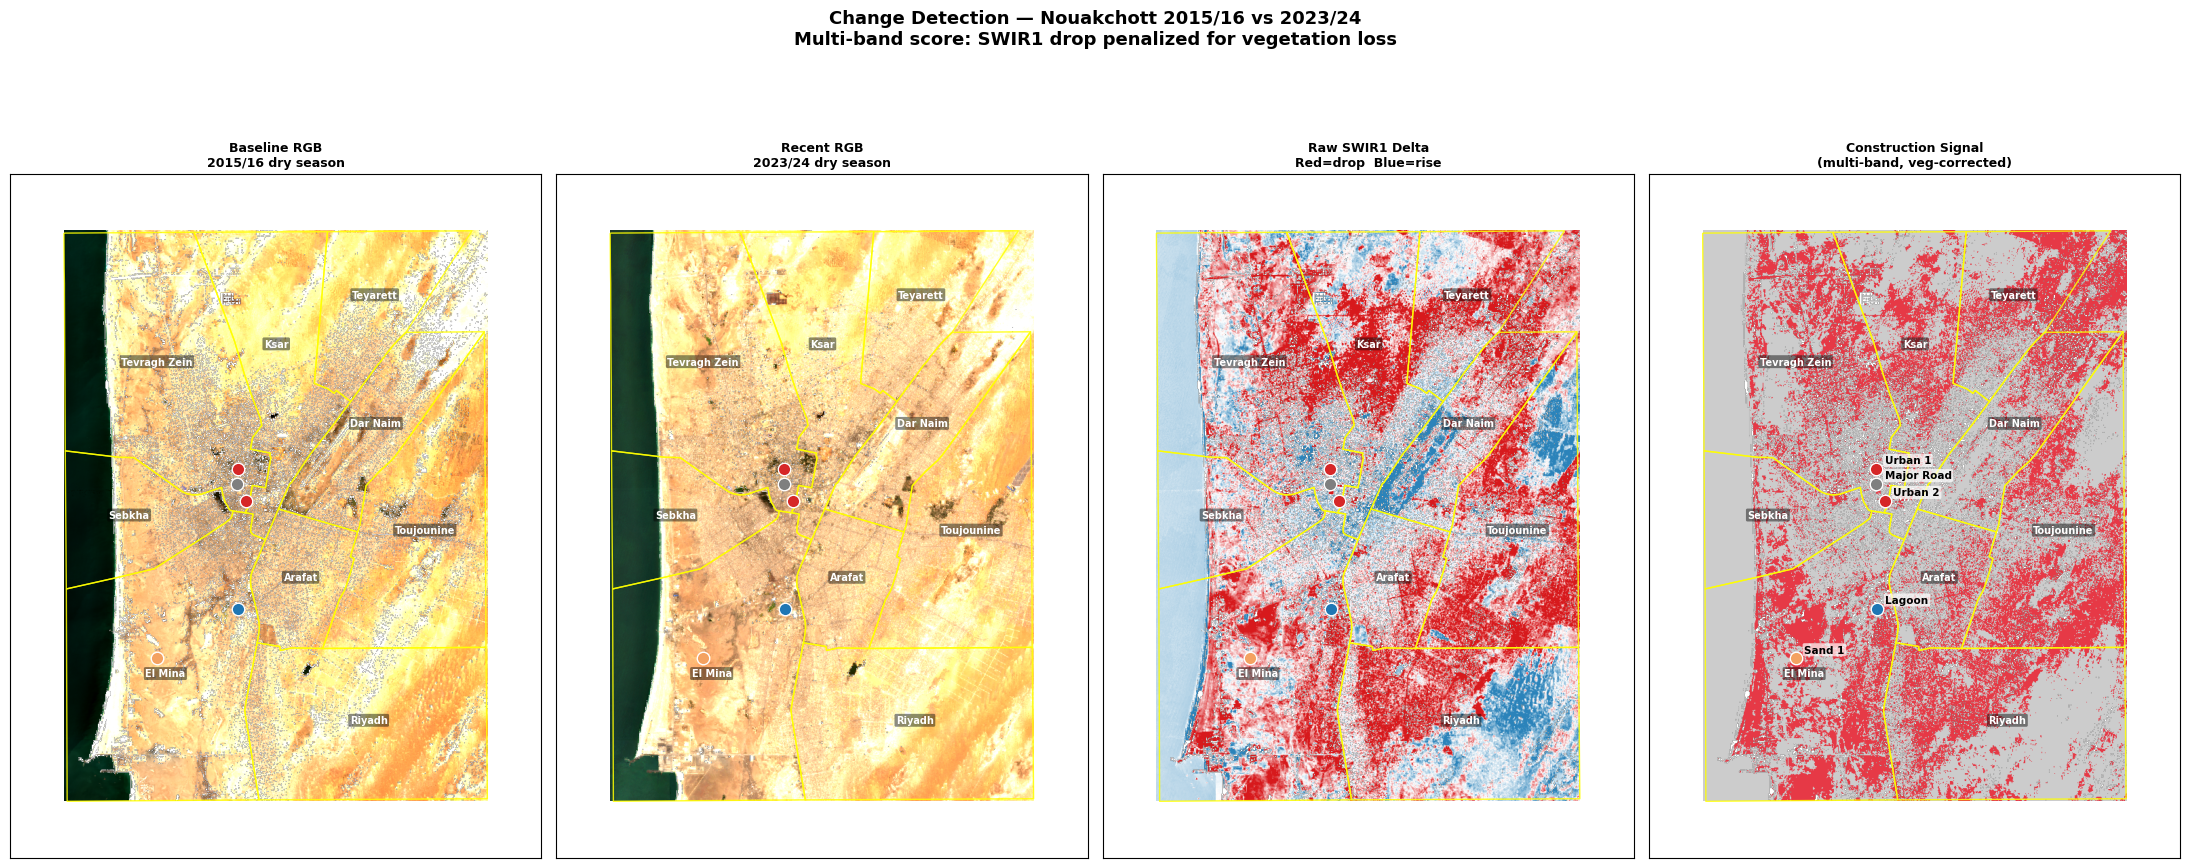


Construction pixel count per moughataa (2016→2024):
Moughataa              New pixels   Area km²   % zone
-------------------------------------------------------
Arafat                     40,890       0.00    27.3%
Dar Naim                   63,428       0.00    29.7%
El Mina                   256,209       0.01    37.8%
Ksar                      107,385       0.00    32.6%
Riyadh                    159,986       0.00    29.1%
Sebkha                     30,100       0.00    13.3%
Tevragh Zein              167,682       0.01    27.9%
Teyarett                   95,882       0.00    41.6%
Toujounine                204,229       0.00    43.9%


In [8]:
# CELL 8 — Visualize Change Raster
def get_thumb(image, region, bands, vmin, vmax, dims=800, gamma=1.0):
    url = image.getThumbURL({
        'bands': bands, 'min': vmin, 'max': vmax,
        'gamma': gamma, 'region': region,
        'dimensions': dims, 'format': 'png'
    })
    return Image.open(BytesIO(requests.get(url, timeout=90).content))

def get_colored_thumb(image, band, region, palette, vmin, vmax, dims=800):
    url = image.select(band).getThumbURL({
        'min': vmin, 'max': vmax, 'palette': palette,
        'region': region, 'dimensions': dims, 'format': 'png'
    })
    return Image.open(BytesIO(requests.get(url, timeout=90).content))

# Raw deltas
delta_swir1 = (comp_after.select('B11')
               .subtract(comp_before.select('B11'))
               .rename('delta_swir1'))
delta_nir   = (comp_after.select('B8')
               .subtract(comp_before.select('B8'))
               .rename('delta_nir'))
delta_red   = (comp_after.select('B4')
               .subtract(comp_before.select('B4'))
               .rename('delta_red'))

# Multi-band construction score
# Construction: SWIR1 drops moderately, NIR drops moderately
# Vegetation loss: NIR drops strongly (> 0.05), NDVI drops strongly
# We penalize strong NIR drop to suppress vegetation false positives
eps = 1e-10

ndvi_before = (comp_before.select('B8').subtract(comp_before.select('B4'))
               .divide(comp_before.select('B8').add(comp_before.select('B4')).add(eps)))
ndvi_after  = (comp_after.select('B8').subtract(comp_after.select('B4'))
               .divide(comp_after.select('B8').add(comp_after.select('B4')).add(eps)))
delta_ndvi  = ndvi_after.subtract(ndvi_before).rename('delta_ndvi')

# Construction score:
#   positive when SWIR1 drops
#   penalized when NDVI drops strongly (= vegetation, not construction)
construct_score = (delta_swir1.multiply(-1)
                   .subtract(delta_ndvi.multiply(-2).max(ee.Image(0)))
                   .rename('construct_score'))

# Binary: score > 0.02 and delta_ndvi > -0.04 (not strong veg loss)
is_construction = (construct_score.gt(0.02)
                   .And(delta_ndvi.gt(-0.04))
                   .rename('is_construction'))

print('Fetching thumbnails...')
rgb_before      = get_thumb(comp_before, region_ee, ['B4','B3','B2'], 0.02, 0.30)
rgb_after       = get_thumb(comp_after,  region_ee, ['B4','B3','B2'], 0.02, 0.30)
delta_thumb     = get_colored_thumb(delta_swir1, 'delta_swir1', region_ee,
                                    ['d7191c','ffffff','2b83ba'], -0.08, 0.08)
construct_thumb = get_colored_thumb(is_construction, 'is_construction', region_ee,
                                    ['cccccc','e63946'], 0, 1)
print('Done. Plotting...')

fig, axes = plt.subplots(1, 4, figsize=(22, 10))
fig.suptitle('Change Detection — Nouakchott 2015/16 vs 2023/24\n'
             'Multi-band score: SWIR1 drop penalized for vegetation loss',
             fontsize=13, fontweight='bold')

minx, miny, maxx, maxy = bounds
buf = 0.02
titles = [
    'Baseline RGB\n2015/16 dry season',
    'Recent RGB\n2023/24 dry season',
    'Raw SWIR1 Delta\nRed=drop  Blue=rise',
    'Construction Signal\n(multi-band, veg-corrected)',
]
for ax, img, title in zip(axes, [rgb_before,rgb_after,delta_thumb,construct_thumb], titles):
    ax.imshow(img, extent=[minx, maxx, miny, maxy], origin='upper')
    ax.set_aspect('equal')
    ax.set_xlim(minx - buf, maxx + buf)
    ax.set_ylim(miny - buf, maxy + buf)
    gdf.boundary.plot(ax=ax, color='yellow', linewidth=1.0, alpha=0.85)
    for _, row in gdf.iterrows():
        ax.annotate(row['ADM2_EN'],
                    (row.geometry.centroid.x, row.geometry.centroid.y),
                    fontsize=7, color='white', ha='center', fontweight='bold',
                    bbox=dict(boxstyle='round,pad=0.15',
                              facecolor='black', alpha=0.45, linewidth=0))
    ax.set_title(title, fontsize=9, fontweight='bold')
    ax.set_xticks([]); ax.set_yticks([])

# Ground truth points on all panels
for name, info in GROUND_TRUTH.items():
    c = TYPE_COLORS[info['type']]
    for ax in axes:
        ax.plot(info['lon'], info['lat'], 'o', color=c,
                ms=9, markeredgecolor='white', markeredgewidth=1.0)
    axes[3].annotate(name, (info['lon'], info['lat']),
                     textcoords='offset points', xytext=(6, 4),
                     fontsize=7.5, color='black', fontweight='bold',
                     bbox=dict(boxstyle='round,pad=0.15',
                               facecolor='white', alpha=0.7, linewidth=0))

plt.tight_layout()
plt.savefig('/outputs/gt_02_change_detection.png', dpi=150, bbox_inches='tight')
plt.show()

# Also print the construction pixel count per moughataa
print('\nConstruction pixel count per moughataa (2016→2024):')
print(f'{"Moughataa":20s} {"New pixels":>12s} {"Area km²":>10s} {"% zone":>8s}')
print('-' * 55)
for _, row in gdf.iterrows():
    geom_ee = ee.Geometry(
        _json.loads(gpd.GeoSeries([row.geometry], crs='EPSG:4326').to_json())
        ['features'][0]['geometry']
    )
    total = is_construction.reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=geom_ee, scale=10,
        maxPixels=1e10, bestEffort=True
    ).getInfo()
    count_all = is_construction.reduceRegion(
        reducer=ee.Reducer.count(),
        geometry=geom_ee, scale=10,
        maxPixels=1e10, bestEffort=True
    ).getInfo()
    n_new  = total.get('is_construction', 0) or 0
    n_all  = count_all.get('is_construction', 1) or 1
    pct    = 100 * n_new / n_all
    area   = row['Shape_Area'] if 'Shape_Area' in row else 0
    print(f"{row['ADM2_EN']:20s} {n_new:>12,.0f} {area:>10.2f} {pct:>7.1f}%")

In [9]:
# CELL 9 — Stable Baseline + Tighter Threshold
print('Building stable 3-year baseline (2015-2018)...')
comp_baseline, n_base = build_composite('2015-10-01', '2018-04-01', region_ee)
print(f'Stable baseline: {n_base} images')

# Recompute deltas with stable baseline
eps = 1e-10

delta_swir1_s = (comp_after.select('B11')
                 .subtract(comp_baseline.select('B11'))
                 .rename('delta_swir1'))

ndvi_base  = (comp_baseline.select('B8').subtract(comp_baseline.select('B4'))
              .divide(comp_baseline.select('B8').add(comp_baseline.select('B4')).add(eps)))
ndvi_after = (comp_after.select('B8').subtract(comp_after.select('B4'))
              .divide(comp_after.select('B8').add(comp_after.select('B4')).add(eps)))
delta_ndvi_s = ndvi_after.subtract(ndvi_base).rename('delta_ndvi')

# Tighter construction score:
#   SWIR1 must drop by at least 0.04 (was 0.02 — now 2x stricter)
#   NDVI must NOT drop strongly (excludes vegetation loss)
#   Also require that AFTER image has reasonable SWIR1 (not water/sebkha)
after_swir1 = comp_after.select('B11')

is_construction_v2 = (
    delta_swir1_s.lt(-0.04)           # meaningful SWIR1 drop
    .And(delta_ndvi_s.gt(-0.03))      # not vegetation loss
    .And(after_swir1.gt(0.15))        # not water/sebkha
    .rename('is_construction')
)

# Revalidate at known points
print('\nValidation at known points with stable baseline:')
print(f'{"Point":12s} {"Type":6s} {"B11_base":>10s} {"B11_after":>10s} {"delta":>8s}  Result')
print('-' * 65)
for name, info in GROUND_TRUTH.items():
    point = ee.Geometry.Point([info['lon'], info['lat']]).buffer(30)
    vb = comp_baseline.select('B11').reduceRegion(
        reducer=ee.Reducer.mean(), geometry=point,
        scale=10, maxPixels=1e6).getInfo()
    va = comp_after.select('B11').reduceRegion(
        reducer=ee.Reducer.mean(), geometry=point,
        scale=10, maxPixels=1e6).getInfo()
    bef = round(float(vb['B11']), 4) if vb.get('B11') else float('nan')
    aft = round(float(va['B11']), 4) if va.get('B11') else float('nan')
    d   = round(aft - bef, 4)
    flag = 'construction?' if d < -0.04 else 'stable'
    print(f'{name:12s} {info["type"]:6s} {bef:>10.4f} {aft:>10.4f} {d:>8.4f}  {flag}')

# Pixel counts with tighter threshold
print('\nConstruction pixels per moughataa (stable baseline, threshold -0.04):')
print(f'{"Moughataa":20s} {"New pixels":>12s} {"% zone":>8s}')
print('-' * 45)
for _, row in gdf.iterrows():
    geom_ee = ee.Geometry(
        _json.loads(gpd.GeoSeries([row.geometry], crs='EPSG:4326').to_json())
        ['features'][0]['geometry']
    )
    n_new = is_construction_v2.reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=geom_ee, scale=10,
        maxPixels=1e10, bestEffort=True
    ).getInfo().get('is_construction', 0) or 0

    n_all = is_construction_v2.reduceRegion(
        reducer=ee.Reducer.count(),
        geometry=geom_ee, scale=10,
        maxPixels=1e10, bestEffort=True
    ).getInfo().get('is_construction', 1) or 1

    pct = 100 * n_new / n_all
    print(f"{row['ADM2_EN']:20s} {n_new:>12,.0f} {pct:>7.1f}%")

print('\nExpected: percentages in 5-20% range for growing zones')
print('(Toujounine and Dar Naim should be highest)')

Building stable 3-year baseline (2015-2018)...
  2015-10-01 to 2018-04-01: 52 images
Stable baseline: 52 images

Validation at known points with stable baseline:
Point        Type     B11_base  B11_after    delta  Result
-----------------------------------------------------------------
Urban 1      urban      0.3745     0.3591  -0.0154  stable
Urban 2      urban      0.3419     0.3581   0.0162  stable
Sand 1       sand       0.4289     0.4331   0.0042  stable
Sand 2       sand       0.7110     0.7303   0.0193  stable
Lagoon       water      0.1452     0.2302   0.0850  stable
Major Road   road       0.2966     0.2817  -0.0149  stable

Construction pixels per moughataa (stable baseline, threshold -0.04):
Moughataa              New pixels   % zone
---------------------------------------------
Arafat                     50,670    29.3%
Dar Naim                   65,009    27.4%
El Mina                   179,469    24.7%
Ksar                       76,580    22.7%
Riyadh                    1

Sampled 486 pixels

delta_SWIR1 distribution:
count    486.0000
mean      -0.0241
std        0.0601
min       -0.2494
25%       -0.0553
50%       -0.0201
75%        0.0144
max        0.4863
Name: delta, dtype: float64

Percentiles:
  p05: -0.1176
  p10: -0.0976
  p25: -0.0553
  p50: -0.0201
  p75: +0.0144
  p90: +0.0284
  p95: +0.0473

How many pixels below various thresholds:
  delta < -0.02:  245 pixels  (50.4%)
  delta < -0.03:  197 pixels  (40.5%)
  delta < -0.04:  161 pixels  (33.1%)
  delta < -0.05:  138 pixels  (28.4%)
  delta < -0.06:  112 pixels  (23.0%)
  delta < -0.08:   69 pixels  (14.2%)
  delta < -0.10:   44 pixels  (9.1%)


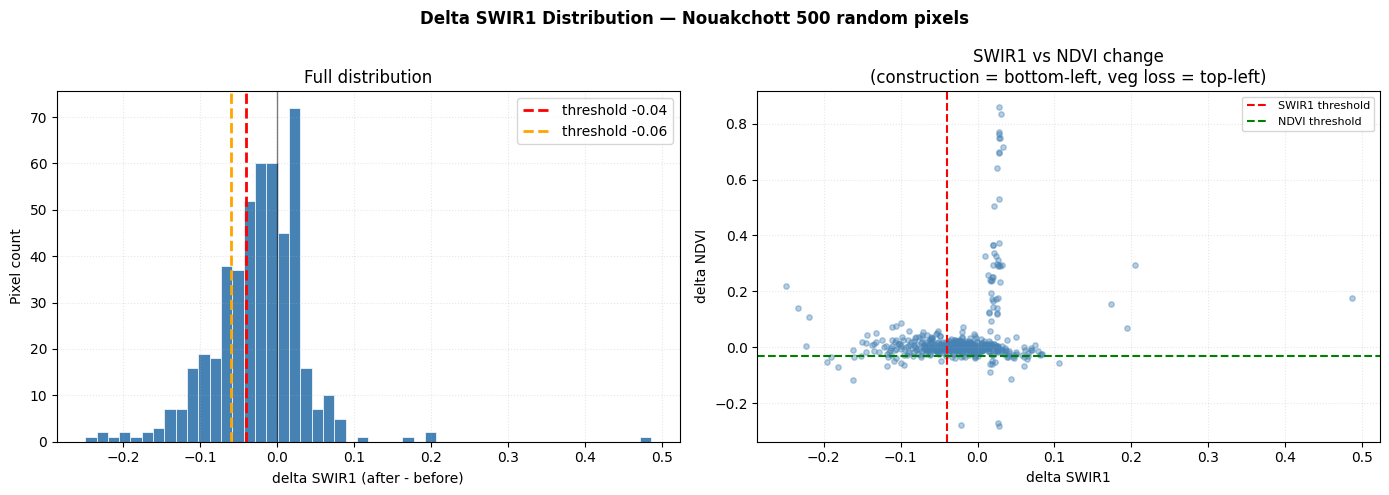

In [10]:
# CELL 10 — Diagnose the delta distribution
# Sample 500 random points across Nouakchott
# See the actual histogram of delta_SWIR1 values

sample = delta_swir1_s.rename('delta').addBands(
    comp_after.select('B11').rename('swir1_after')
).addBands(
    delta_ndvi_s.rename('delta_ndvi')
)

# Random sample of 500 pixels inside Nouakchott
pts = sample.sample(
    region   = region_ee,
    scale    = 30,
    numPixels= 500,
    seed     = 42,
    geometries=False
).getInfo()

vals = [f['properties'] for f in pts['features']]
df_sample = pd.DataFrame(vals)

print(f'Sampled {len(df_sample)} pixels')
print()
print('delta_SWIR1 distribution:')
print(df_sample['delta'].describe().round(4))
print()
print('Percentiles:')
for p in [5, 10, 25, 50, 75, 90, 95]:
    v = df_sample['delta'].quantile(p/100)
    print(f'  p{p:02d}: {v:+.4f}')

print()
print('How many pixels below various thresholds:')
for thresh in [-0.02, -0.03, -0.04, -0.05, -0.06, -0.08, -0.10]:
    n   = (df_sample['delta'] < thresh).sum()
    pct = 100 * n / len(df_sample)
    print(f'  delta < {thresh:+.2f}: {n:>4d} pixels  ({pct:.1f}%)')

# Plot histogram
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Delta SWIR1 Distribution — Nouakchott 500 random pixels',
             fontsize=12, fontweight='bold')

ax = axes[0]
ax.hist(df_sample['delta'], bins=50, color='steelblue',
        edgecolor='white', linewidth=0.5)
ax.axvline(-0.04, color='red',    lw=2, ls='--', label='threshold -0.04')
ax.axvline(-0.06, color='orange', lw=2, ls='--', label='threshold -0.06')
ax.axvline(0,     color='black',  lw=1, alpha=0.5)
ax.set_xlabel('delta SWIR1 (after - before)')
ax.set_ylabel('Pixel count')
ax.set_title('Full distribution')
ax.legend()
ax.grid(alpha=0.3, ls=':')

ax = axes[1]
ax.scatter(df_sample['delta'], df_sample['delta_ndvi'],
           alpha=0.4, s=15, c='steelblue')
ax.axvline(-0.04, color='red',   lw=1.5, ls='--', label='SWIR1 threshold')
ax.axhline(-0.03, color='green', lw=1.5, ls='--', label='NDVI threshold')
ax.set_xlabel('delta SWIR1')
ax.set_ylabel('delta NDVI')
ax.set_title('SWIR1 vs NDVI change\n(construction = bottom-left, veg loss = top-left)')
ax.legend(fontsize=8)
ax.grid(alpha=0.3, ls=':')

plt.tight_layout()
plt.savefig('/outputs/gt_03_delta_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

In [11]:
# CELL 11 — Check Sentinel-1 data availability over Nouakchott
s1_col = (ee.ImageCollection('COPERNICUS/S1_GRD')
            .filterBounds(region_ee)
            .filterDate('2015-01-01', '2024-12-31')
            .filter(ee.Filter.eq('instrumentMode', 'IW'))
            .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV'))
            .filter(ee.Filter.eq('orbitProperties_pass', 'DESCENDING')))

n_total = s1_col.size().getInfo()

# Count per year
print('Sentinel-1 IW VV image counts over Nouakchott:')
print(f'Total 2015-2024: {n_total} images')
print()
print(f'{"Year":6s}  {"Images":>8s}')
print('-' * 18)
for year in range(2015, 2025):
    n = (s1_col
         .filterDate(f'{year}-01-01', f'{year}-12-31')
         .size().getInfo())
    bar = '█' * (n // 3)
    print(f'{year}    {n:>4d}  {bar}')

# Check available bands
sample_img = s1_col.first()
band_names = sample_img.bandNames().getInfo()
print(f'\nAvailable bands: {band_names}')
print('VV = vertical transmit/vertical receive — best for urban detection')
print('VH = vertical transmit/horizontal receive — sensitive to volume scattering')

Sentinel-1 IW VV image counts over Nouakchott:
Total 2015-2024: 0 images

Year      Images
------------------
2015       0  
2016       0  
2017       0  
2018       0  
2019       0  
2020       0  
2021       0  
2022       0  
2023       0  
2024       0  


EEException: Image.bandNames: Parameter 'image' is required and may not be null.

In [12]:
# CELL 12 — Check S1 with all orbit passes
for orbit in ['DESCENDING', 'ASCENDING']:
    col = (ee.ImageCollection('COPERNICUS/S1_GRD')
             .filterBounds(region_ee)
             .filterDate('2015-01-01', '2024-12-31')
             .filter(ee.Filter.eq('instrumentMode', 'IW'))
             .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV'))
             .filter(ee.Filter.eq('orbitProperties_pass', orbit)))
    n = col.size().getInfo()
    print(f'{orbit}: {n} images')

# Also try without any orbit filter
col_all = (ee.ImageCollection('COPERNICUS/S1_GRD')
             .filterBounds(region_ee)
             .filterDate('2015-01-01', '2024-12-31')
             .filter(ee.Filter.eq('instrumentMode', 'IW')))
n_all = col_all.size().getInfo()
print(f'ALL orbits combined: {n_all} images')

if n_all > 0:
    # Check what modes/polarisations are actually available
    sample = col_all.first().getInfo()
    props  = sample['properties']
    print(f'\nFirst image properties:')
    print(f'  Date           : {props.get("system:time_start")}')
    print(f'  Orbit pass     : {props.get("orbitProperties_pass")}')
    print(f'  Polarisations  : {props.get("transmitterReceiverPolarisation")}')
    print(f'  Instrument mode: {props.get("instrumentMode")}')
    bands = list(sample['bands'])
    print(f'  Bands          : {[b["id"] for b in bands]}')

DESCENDING: 0 images
ASCENDING: 257 images
ALL orbits combined: 257 images

First image properties:
  Date           : 1428433827320
  Orbit pass     : ASCENDING
  Polarisations  : ['VV', 'VH']
  Instrument mode: IW
  Bands          : ['VV', 'VH', 'angle']


In [13]:
# CELL 13 — Yearly coverage + VV backscatter at known points
s1_col = (ee.ImageCollection('COPERNICUS/S1_GRD')
            .filterBounds(region_ee)
            .filterDate('2015-01-01', '2024-12-31')
            .filter(ee.Filter.eq('instrumentMode', 'IW'))
            .filter(ee.Filter.eq('orbitProperties_pass', 'ASCENDING'))
            .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV')))

print('Sentinel-1 ASCENDING coverage:')
print(f'{"Year":6s}  {"Images":>6s}  {"Bar"}')
print('-' * 35)
for year in range(2015, 2025):
    n = s1_col.filterDate(f'{year}-01-01', f'{year}-12-31').size().getInfo()
    bar = '█' * n
    print(f'{year}    {n:>4d}  {bar}')

# Build annual VV composites (median) for two periods
def build_s1_composite(date_start, date_end):
    col = (s1_col
             .filterDate(date_start, date_end)
             .select(['VV','VH']))
    n = col.size().getInfo()
    print(f'  {date_start} to {date_end}: {n} images')
    return col.median(), n

print('\nBuilding S1 composites...')
s1_before, nb = build_s1_composite('2016-01-01', '2018-12-31')
s1_after,  na = build_s1_composite('2021-01-01', '2024-12-31')

# Sample VV at known points — KEY TEST
# Expected: urban >> sand in VV backscatter
print('\nVV Backscatter (dB) at known points:')
print(f'{"Point":12s} {"Type":6s} {"VV_before":>10s} {"VV_after":>10s} {"VH_before":>10s} {"VH_after":>10s}')
print('-' * 65)

records_s1 = []
for name, info in GROUND_TRUTH.items():
    pt = ee.Geometry.Point([info['lon'], info['lat']]).buffer(50)

    vb = s1_before.select(['VV','VH']).reduceRegion(
        reducer=ee.Reducer.mean(), geometry=pt,
        scale=10, maxPixels=1e6).getInfo()
    va = s1_after.select(['VV','VH']).reduceRegion(
        reducer=ee.Reducer.mean(), geometry=pt,
        scale=10, maxPixels=1e6).getInfo()

    vv_b = round(float(vb['VV']), 2) if vb.get('VV') else float('nan')
    vv_a = round(float(va['VV']), 2) if va.get('VV') else float('nan')
    vh_b = round(float(vb['VH']), 2) if vb.get('VH') else float('nan')
    vh_a = round(float(va['VH']), 2) if va.get('VH') else float('nan')

    records_s1.append({
        'point': name, 'type': info['type'],
        'VV_before': vv_b, 'VV_after': vv_a,
        'VH_before': vh_b, 'VH_after': vh_a,
        'VV_delta': round(vv_a - vv_b, 2)
    })
    print(f'{name:12s} {info["type"]:6s} {vv_b:>10.2f} {vv_a:>10.2f} {vh_b:>10.2f} {vh_a:>10.2f}')

df_s1 = pd.DataFrame(records_s1).set_index('point')

print('\nExpected:')
print('  Urban >> Sand in VV  (typically 5-8 dB difference)')
print('  Water very low VV    (typically < -15 dB)')
print('  Sand low VV          (smooth surface, typically -12 to -8 dB)')
print('  Urban high VV        (rough/structured surface, typically -6 to 0 dB)')


Sentinel-1 ASCENDING coverage:
Year    Images  Bar
-----------------------------------
2015      13  █████████████
2016      18  ██████████████████
2017      31  ███████████████████████████████
2018      30  ██████████████████████████████
2019      31  ███████████████████████████████
2020      30  ██████████████████████████████
2021      30  ██████████████████████████████
2022      24  ████████████████████████
2023      25  █████████████████████████
2024      24  ████████████████████████

Building S1 composites...
  2016-01-01 to 2018-12-31: 79 images
  2021-01-01 to 2024-12-31: 104 images

VV Backscatter (dB) at known points:
Point        Type    VV_before   VV_after  VH_before   VH_after
-----------------------------------------------------------------
Urban 1      urban       -9.97      -9.20     -14.95     -14.83
Urban 2      urban       -7.66      -7.96     -14.43     -15.22
Sand 1       sand       -20.58     -21.01     -28.15     -27.42
Sand 2       sand       -20.78     -22.76  

In [14]:
# CELL 14 — SAR Urban Map + Validation

# Urban threshold derived from ground truth:
# Urban: -7 to -10 dB | Sand: -20 to -21 dB | Gap at -14 dB
URBAN_THRESHOLD_DB = -14.0

# Apply threshold to after composite
urban_mask = s1_after.select('VV').gt(URBAN_THRESHOLD_DB).rename('urban')

# Also compute VV change (urban expansion signal)
vv_delta = s1_after.select('VV').subtract(s1_before.select('VV')).rename('vv_delta')

# New construction: was below threshold before, above after
new_construction = (s1_before.select('VV').lt(URBAN_THRESHOLD_DB)
                    .And(s1_after.select('VV').gt(URBAN_THRESHOLD_DB))
                    .rename('new_construction'))

# ── Validate threshold at known points ──────────────────────
print(f'Threshold: {URBAN_THRESHOLD_DB} dB')
print(f'{"Point":12s} {"Type":6s} {"VV_after":>10s} {"Classified":>14s}  {"Correct?"}')
print('-' * 60)
for _, row in df_s1.iterrows():
    vv  = row['VV_after']
    cls = 'urban' if vv > URBAN_THRESHOLD_DB else 'non-urban'
    expected_urban = row['type'] in ['urban', 'road']
    correct = ((cls == 'urban') == expected_urban)
    flag = '✓' if correct else '✗ WRONG'
    print(f'{row.name:12s} {row["type"]:6s} {vv:>10.2f} {cls:>14s}  {flag}')

# ── Zonal statistics ─────────────────────────────────────────
print('\nUrban fraction per moughataa (SAR-based, 2021-2024):')
print(f'{"Moughataa":20s} {"Urban %":>8s} {"New constr%":>12s} {"VV mean(dB)":>12s}')
print('-' * 58)

results_sar = []
for _, row in gdf.iterrows():
    geom_ee = ee.Geometry(
        _json.loads(gpd.GeoSeries([row.geometry], crs='EPSG:4326').to_json())
        ['features'][0]['geometry']
    )

    urban_frac = urban_mask.reduceRegion(
        reducer=ee.Reducer.mean(), geometry=geom_ee,
        scale=10, maxPixels=1e10, bestEffort=True
    ).getInfo().get('urban', 0) or 0

    new_frac = new_construction.reduceRegion(
        reducer=ee.Reducer.mean(), geometry=geom_ee,
        scale=10, maxPixels=1e10, bestEffort=True
    ).getInfo().get('new_construction', 0) or 0

    vv_mean = s1_after.select('VV').reduceRegion(
        reducer=ee.Reducer.mean(), geometry=geom_ee,
        scale=10, maxPixels=1e10, bestEffort=True
    ).getInfo().get('VV', float('nan'))

    results_sar.append({
        'moughataa'    : row['ADM2_EN'],
        'urban_frac'   : round(urban_frac * 100, 1),
        'new_constr_frac': round(new_frac * 100, 1),
        'vv_mean_db'   : round(vv_mean, 2) if vv_mean else float('nan'),
    })
    print(f"{row['ADM2_EN']:20s} {urban_frac*100:>7.1f}% {new_frac*100:>11.1f}% {vv_mean:>11.2f}")

df_sar = pd.DataFrame(results_sar)

print('\nExpected ranking (most → least urban):')
print('  Ksar, Tevragh Zein, Arafat > Toujounine, Dar Naim > Riyadh, Teyarett')

Threshold: -14.0 dB
Point        Type     VV_after     Classified  Correct?
------------------------------------------------------------
Urban 1      urban       -9.20          urban  ✓
Urban 2      urban       -7.96          urban  ✓
Sand 1       sand       -21.01      non-urban  ✓
Sand 2       sand       -22.76      non-urban  ✓
Lagoon       water      -13.46          urban  ✗ WRONG
Major Road   road        -7.24          urban  ✓

Urban fraction per moughataa (SAR-based, 2021-2024):
Moughataa             Urban %  New constr%  VV mean(dB)
----------------------------------------------------------
Arafat                  97.4%         2.4%       -8.15
Dar Naim                72.4%        10.1%      -11.49
El Mina                 38.8%         7.3%      -14.71
Ksar                    46.2%        12.3%      -14.65
Riyadh                  35.6%         6.2%      -14.99
Sebkha                  36.6%         6.8%      -15.01
Tevragh Zein            43.0%         7.6%      -13.85
Teyarett 

Fetching thumbnails...
Done. Plotting...


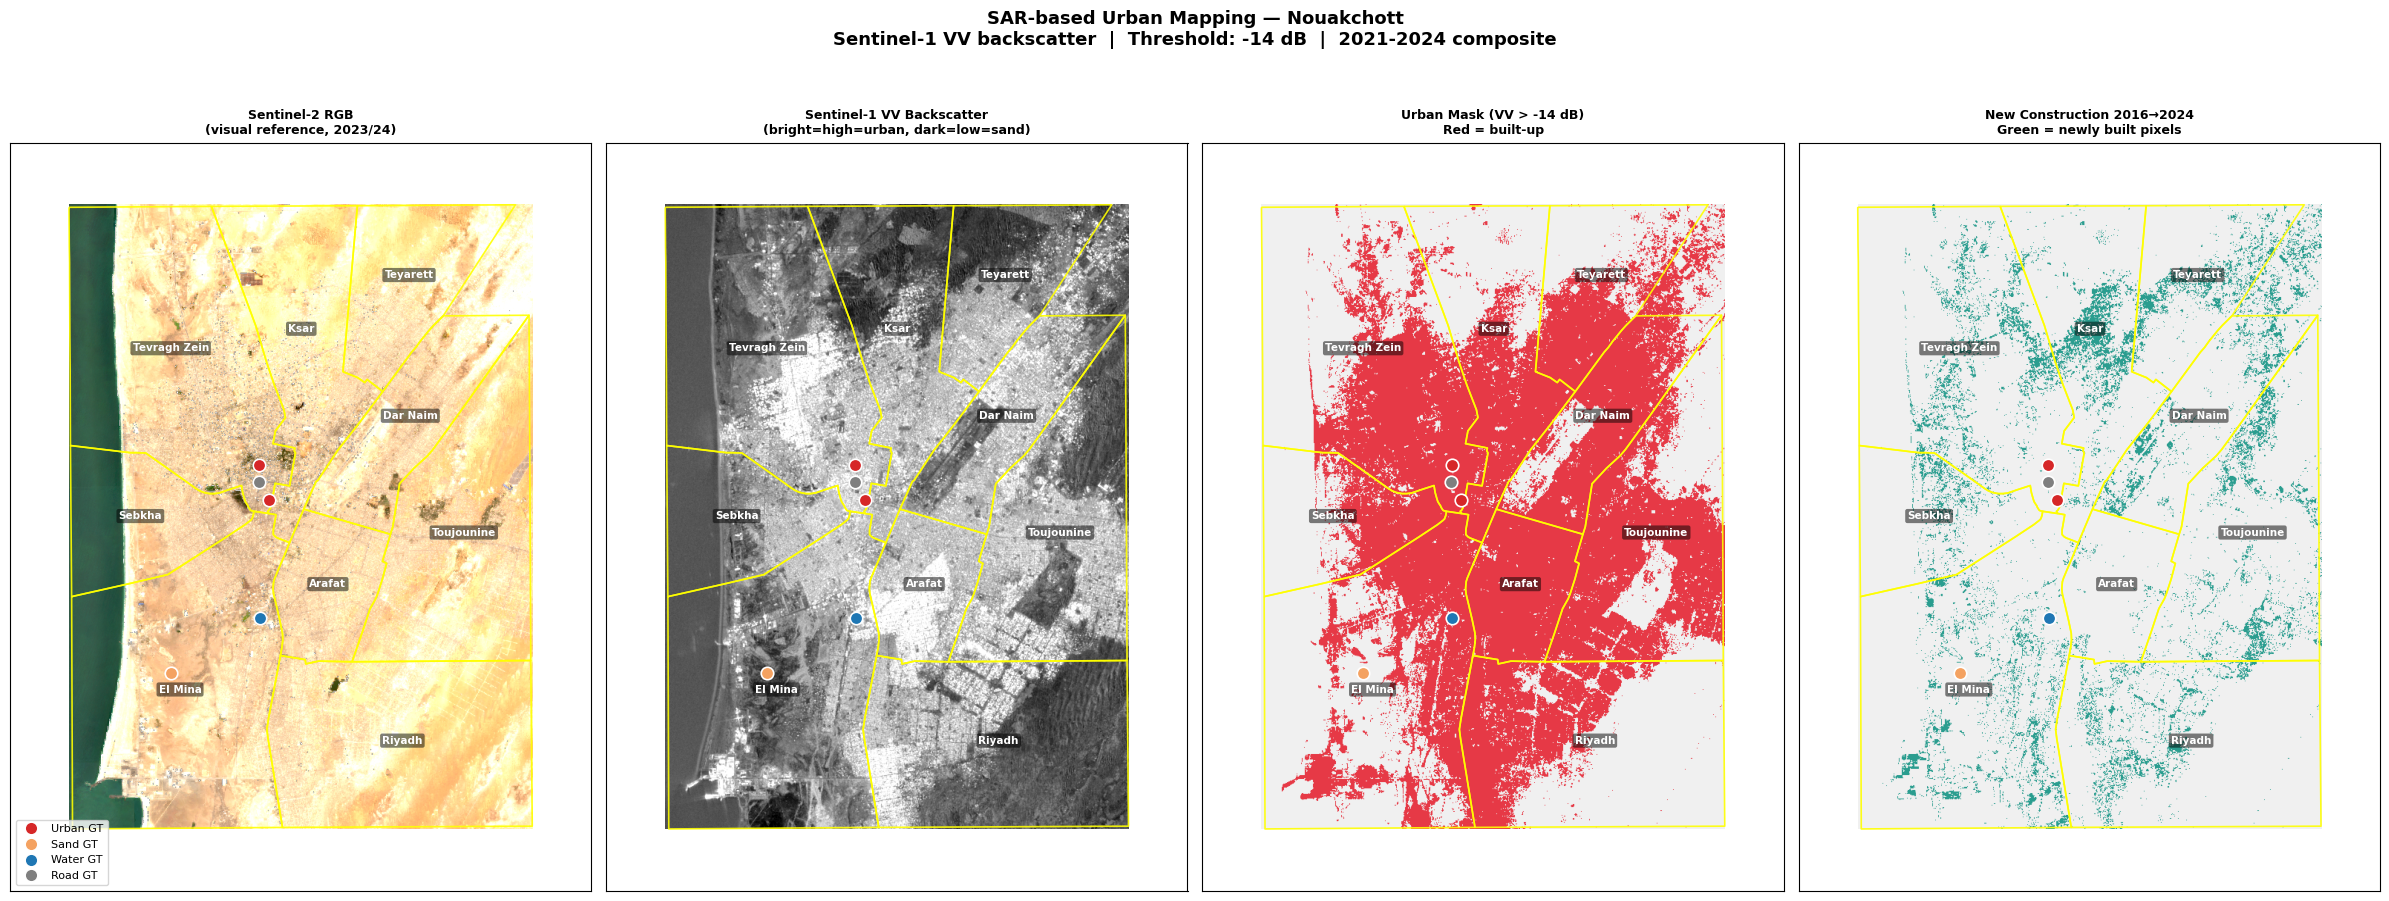

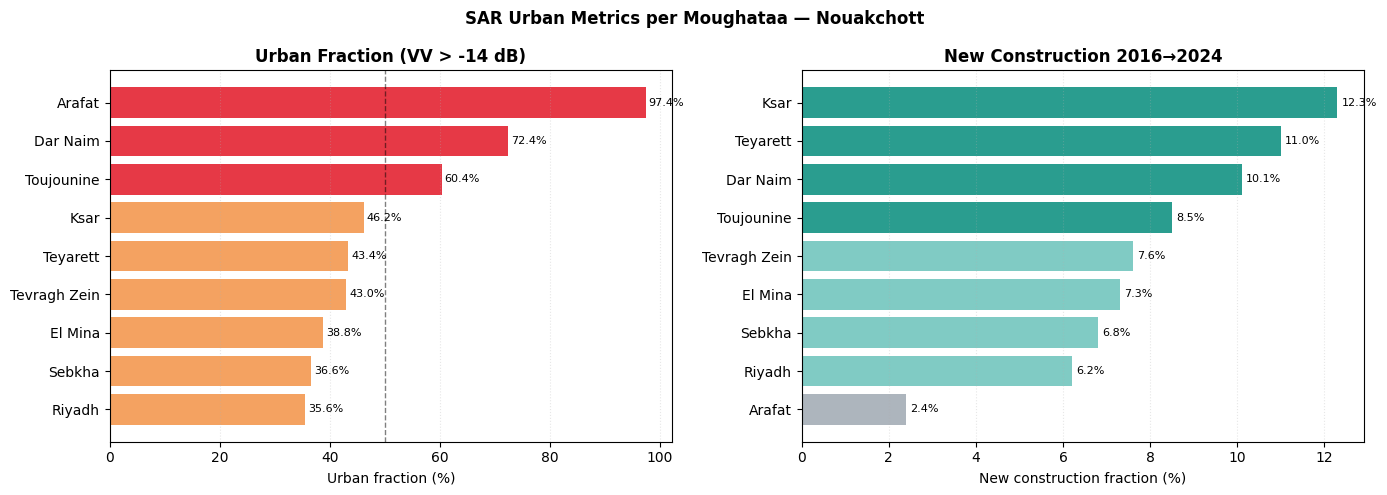

In [15]:
# CELL 15 — Visualize SAR urban map before any changes

def get_colored_thumb(image, band, region, palette, vmin, vmax, dims=800):
    url = image.select(band).getThumbURL({
        'min': vmin, 'max': vmax, 'palette': palette,
        'region': region, 'dimensions': dims, 'format': 'png'
    })
    return Image.open(BytesIO(requests.get(url, timeout=90).content))

def get_thumb(image, region, bands, vmin, vmax, dims=800, gamma=1.0):
    url = image.getThumbURL({
        'bands': bands, 'min': vmin, 'max': vmax,
        'gamma': gamma, 'region': region,
        'dimensions': dims, 'format': 'png'
    })
    return Image.open(BytesIO(requests.get(url, timeout=90).content))

minx, miny, maxx, maxy = bounds
buf = 0.02

print('Fetching thumbnails...')

# Panel 1: Sentinel-2 RGB for visual reference
rgb = get_thumb(comp_after, region_ee, ['B4','B3','B2'], 0.02, 0.30, gamma=1.4)

# Panel 2: Raw VV backscatter (dB) — greyscale
vv_thumb = get_colored_thumb(
    s1_after, 'VV', region_ee,
    palette=['000000','404040','808080','c0c0c0','ffffff'],
    vmin=-25, vmax=-5
)

# Panel 3: Urban mask at -14 dB threshold
urban_thumb = get_colored_thumb(
    urban_mask, 'urban', region_ee,
    palette=['f0f0f0','e63946'],
    vmin=0, vmax=1
)

# Panel 4: New construction signal
new_thumb = get_colored_thumb(
    new_construction, 'new_construction', region_ee,
    palette=['f0f0f0','2a9d8f'],
    vmin=0, vmax=1
)

print('Done. Plotting...')

fig, axes = plt.subplots(1, 4, figsize=(24, 10))
fig.suptitle(
    'SAR-based Urban Mapping — Nouakchott\n'
    'Sentinel-1 VV backscatter  |  Threshold: -14 dB  |  2021-2024 composite',
    fontsize=13, fontweight='bold'
)

panels = [
    (rgb,          'Sentinel-2 RGB\n(visual reference, 2023/24)'),
    (vv_thumb,     'Sentinel-1 VV Backscatter\n(bright=high=urban, dark=low=sand)'),
    (urban_thumb,  'Urban Mask (VV > -14 dB)\nRed = built-up'),
    (new_thumb,    'New Construction 2016→2024\nGreen = newly built pixels'),
]

for ax, (img, title) in zip(axes, panels):
    ax.imshow(img, extent=[minx, maxx, miny, maxy], origin='upper')
    ax.set_aspect('equal')
    ax.set_xlim(minx - buf, maxx + buf)
    ax.set_ylim(miny - buf, maxy + buf)
    gdf.boundary.plot(ax=ax, color='yellow', linewidth=1.2, alpha=0.9)
    for _, row in gdf.iterrows():
        ax.annotate(
            row['ADM2_EN'],
            (row.geometry.centroid.x, row.geometry.centroid.y),
            fontsize=7.5, color='white', ha='center', fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.2',
                      facecolor='black', alpha=0.5, linewidth=0)
        )
    ax.set_title(title, fontsize=9, fontweight='bold')
    ax.set_xticks([]); ax.set_yticks([])

# Mark ground truth points on all panels
for name, info in GROUND_TRUTH.items():
    c = TYPE_COLORS[info['type']]
    for ax in axes:
        ax.plot(info['lon'], info['lat'], 'o', color=c,
                ms=9, markeredgecolor='white', markeredgewidth=1.2)

# Legend for ground truth dots
from matplotlib.lines import Line2D
legend_els = [
    Line2D([0],[0], marker='o', color='w', markerfacecolor=TYPE_COLORS['urban'],
           markersize=9, label='Urban GT'),
    Line2D([0],[0], marker='o', color='w', markerfacecolor=TYPE_COLORS['sand'],
           markersize=9, label='Sand GT'),
    Line2D([0],[0], marker='o', color='w', markerfacecolor=TYPE_COLORS['water'],
           markersize=9, label='Water GT'),
    Line2D([0],[0], marker='o', color='w', markerfacecolor=TYPE_COLORS['road'],
           markersize=9, label='Road GT'),
]
axes[0].legend(handles=legend_els, loc='lower left', fontsize=8, framealpha=0.8)

plt.tight_layout()
plt.savefig('/outputs/gt_04_sar_urban_map.png', dpi=150, bbox_inches='tight')
plt.show()

# Also plot bar chart of urban % per moughataa
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('SAR Urban Metrics per Moughataa — Nouakchott',
             fontsize=12, fontweight='bold')

df_plot = pd.DataFrame(results_sar).sort_values('urban_frac', ascending=True)

ax = axes[0]
colors = ['#e63946' if v > 60 else '#f4a261' if v > 35 else '#adb5bd'
          for v in df_plot['urban_frac']]
ax.barh(df_plot['moughataa'], df_plot['urban_frac'], color=colors)
ax.axvline(50, color='black', lw=1, ls='--', alpha=0.5)
ax.set_xlabel('Urban fraction (%)')
ax.set_title('Urban Fraction (VV > -14 dB)', fontweight='bold')
ax.grid(axis='x', alpha=0.3, ls=':')
for i, (v, name) in enumerate(zip(df_plot['urban_frac'], df_plot['moughataa'])):
    ax.text(v + 0.5, i, f'{v:.1f}%', va='center', fontsize=8)

ax = axes[1]
df_plot2 = pd.DataFrame(results_sar).sort_values('new_constr_frac', ascending=True)
colors2 = ['#2a9d8f' if v > 8 else '#80cbc4' if v > 5 else '#adb5bd'
           for v in df_plot2['new_constr_frac']]
ax.barh(df_plot2['moughataa'], df_plot2['new_constr_frac'], color=colors2)
ax.set_xlabel('New construction fraction (%)')
ax.set_title('New Construction 2016→2024', fontweight='bold')
ax.grid(axis='x', alpha=0.3, ls=':')
for i, (v, name) in enumerate(zip(df_plot2['new_constr_frac'], df_plot2['moughataa'])):
    ax.text(v + 0.1, i, f'{v:.1f}%', va='center', fontsize=8)

plt.tight_layout()
plt.savefig('/outputs/gt_05_sar_bar_charts.png', dpi=150, bbox_inches='tight')
plt.show()

In [17]:
# CELL 16 — Annual SAR Urban Fraction Time Series 2016-2024

THRESHOLD_DB = -14.0
YEARS = list(range(2016, 2025))

# Water mask from Sentinel-2
b3   = comp_after.select('B3')
b8   = comp_after.select('B8')
ndwi = b3.subtract(b8).divide(b3.add(b8).add(1e-10))
water_mask = ndwi.lt(0.0)

print(f'Extracting annual urban fraction per moughataa')
print(f'Threshold: {THRESHOLD_DB} dB | Water masked | Scale: 10m')
print(f'{"":22s}', end='')
for y in YEARS:
    print(f'{y:>8d}', end='')   # fixed: d not s
print()
print('-' * (22 + 8 * len(YEARS)))

records_ts = []
for _, row in gdf.iterrows():
    zone    = row['ADM2_EN']
    geom_ee = ee.Geometry(
        _json.loads(gpd.GeoSeries([row.geometry], crs='EPSG:4326').to_json())
        ['features'][0]['geometry']
    )

    row_ts = {'moughataa': zone}
    print(f'{zone:22s}', end='', flush=True)

    for year in YEARS:
        col_year  = s1_col.filterDate(f'{year}-01-01', f'{year}-12-31').select('VV')
        comp_year = col_year.median()

        urban_year = (comp_year
                      .gt(THRESHOLD_DB)
                      .updateMask(water_mask)
                      .rename('urban'))

        frac = urban_year.reduceRegion(
            reducer    = ee.Reducer.mean(),
            geometry   = geom_ee,
            scale      = 10,
            maxPixels  = 1e10,
            bestEffort = True
        ).getInfo().get('urban', None)

        val = round(frac * 100, 1) if frac is not None else float('nan')
        row_ts[year] = val
        print(f'{val:>8.1f}', end='', flush=True)

    records_ts.append(row_ts)
    print()

df_ts = pd.DataFrame(records_ts).set_index('moughataa')

print('\nFull time series table:')
print(df_ts.to_string())
df_ts.to_csv('/outputs/sar_urban_fraction_timeseries.csv')
print('\nSaved to /outputs/sar_urban_fraction_timeseries.csv')

Extracting annual urban fraction per moughataa
Threshold: -14.0 dB | Water masked | Scale: 10m
                          2016    2017    2018    2019    2020    2021    2022    2023    2024
----------------------------------------------------------------------------------------------
Arafat                    95.5    95.1    95.3    95.9    96.0    96.2    97.2    97.3    97.1
Dar Naim                  71.5    64.4    63.8    65.9    66.5    67.9    71.1    74.7    77.5
El Mina                   42.9    41.3    44.3    45.9    47.8    47.4    48.5    48.7    50.3
Ksar                      33.9    34.3    35.0    37.8    39.5    41.7    44.5    47.2    50.7
Riyadh                    31.2    30.5    30.8    32.1    32.7    33.6    35.4    36.6    40.8
Sebkha                    52.8    53.5    54.6    57.4    60.0    59.7    63.7    64.2    66.1
Tevragh Zein              48.3    47.8    47.4    51.4    53.5    54.0    54.6    55.8    58.1
Teyarett                  32.8    33.0    33.8    

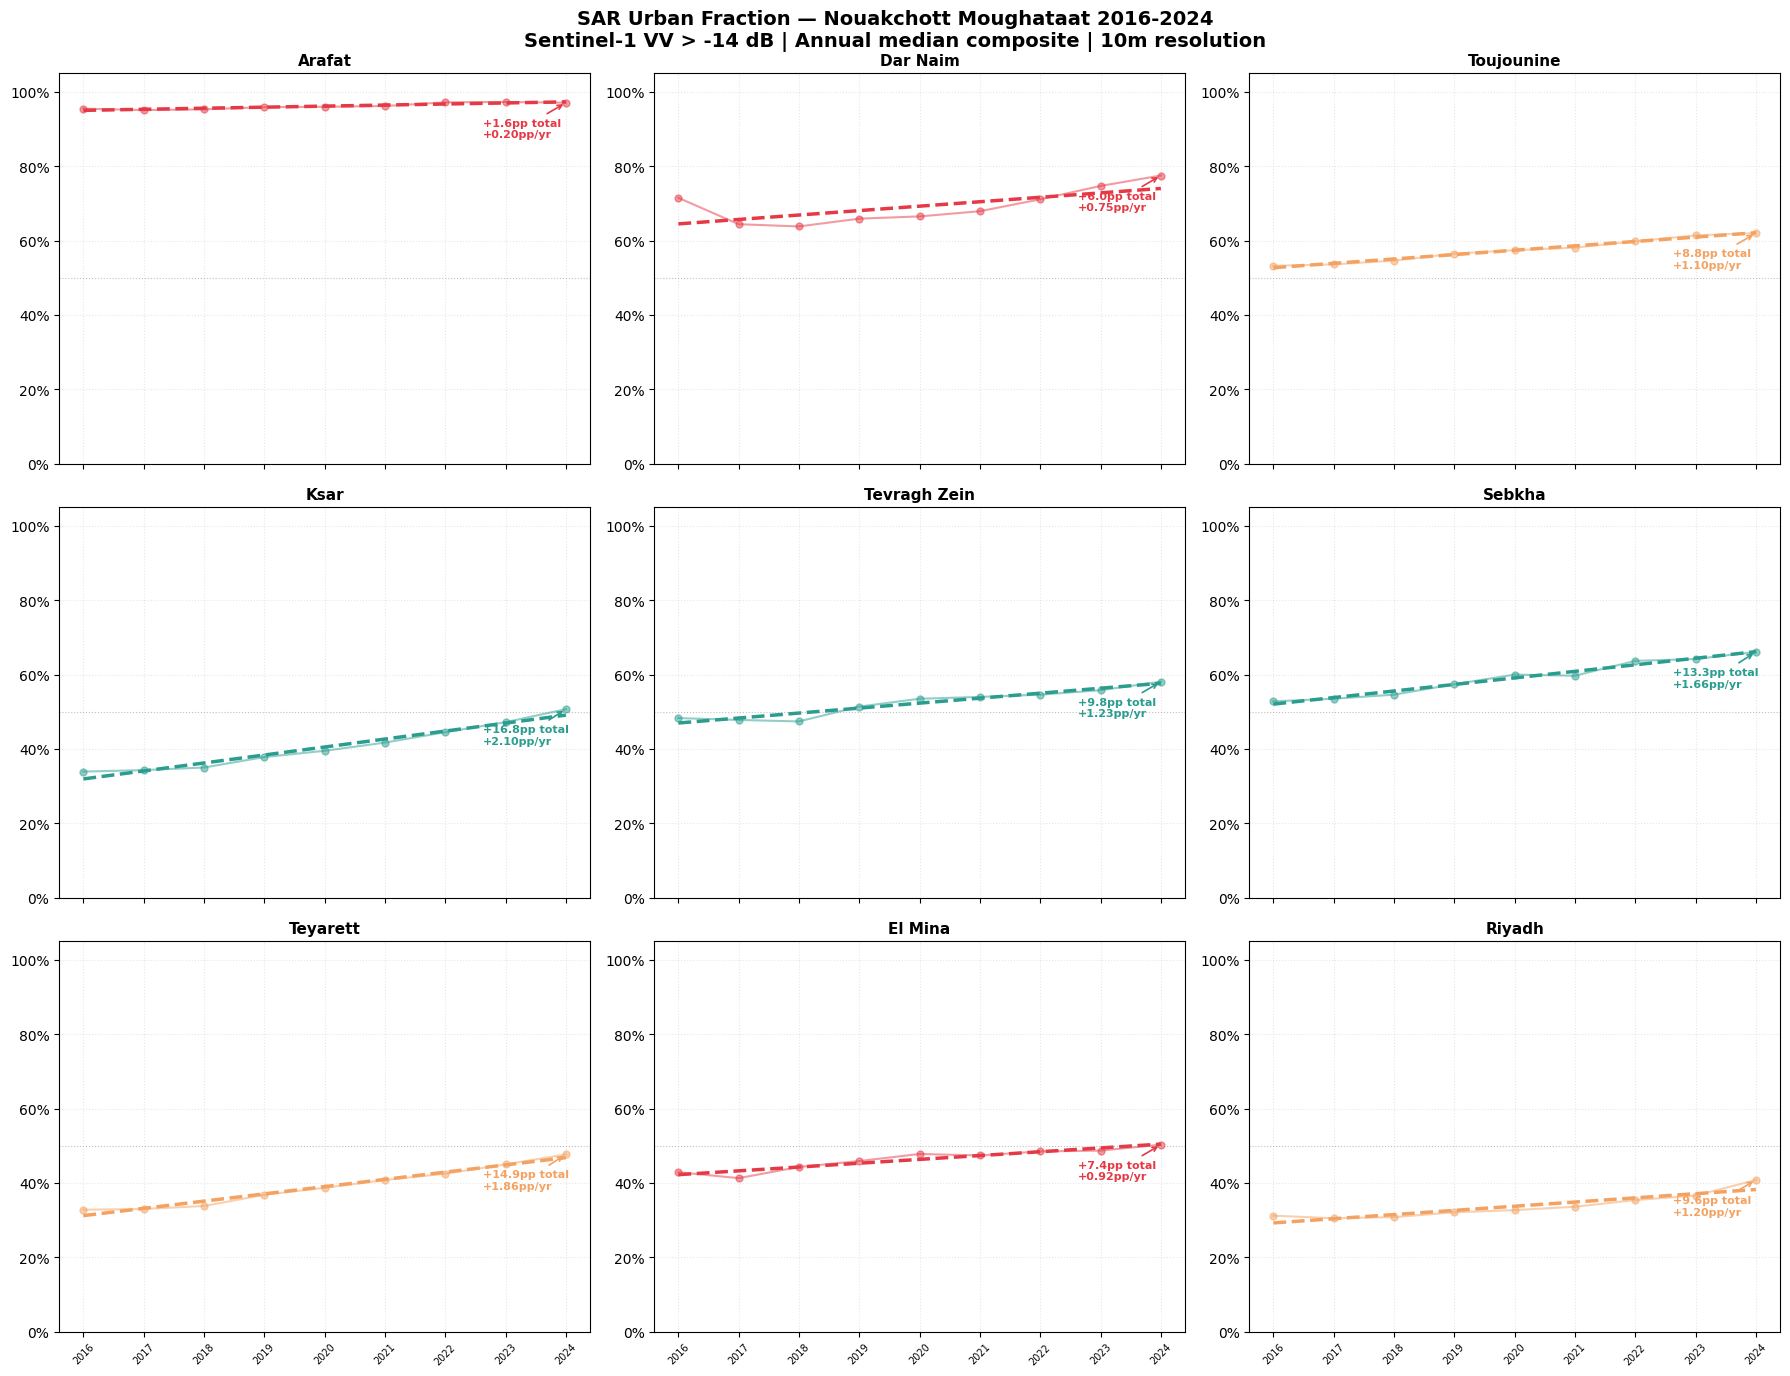

Urban Growth Summary 2016→2024:
Moughataa              2016   2024   Change   Rate/yr  Trajectory
----------------------------------------------------------------------
Arafat                 95.5   97.1     +1.6     +0.20  🟢 slow/stable
Dar Naim               71.5   77.5     +6.0     +0.75  🟢 slow/stable
Toujounine             53.2   62.0     +8.8     +1.10  🟡 moderate growth
Ksar                   33.9   50.7    +16.8     +2.10  🔴 rapid growth
Tevragh Zein           48.3   58.1     +9.8     +1.23  🟡 moderate growth
Sebkha                 52.8   66.1    +13.3     +1.66  🔴 rapid growth
Teyarett               32.8   47.7    +14.9     +1.86  🔴 rapid growth
El Mina                42.9   50.3     +7.4     +0.92  🟡 moderate growth
Riyadh                 31.2   40.8     +9.6     +1.20  🟡 moderate growth

City average 2016: 51.3%
City average 2024: 61.1%
City average change: +9.8pp over 8 years


In [18]:
# CELL 17 — Time Series Visualization

WILAYA_COLORS = {
    'Arafat'      : '#e63946',
    'Dar Naim'    : '#e63946',
    'El Mina'     : '#e63946',
    'Ksar'        : '#2a9d8f',
    'Tevragh Zein': '#2a9d8f',
    'Sebkha'      : '#2a9d8f',
    'Toujounine'  : '#f4a261',
    'Teyarett'    : '#f4a261',
    'Riyadh'      : '#f4a261',
}

fig, axes = plt.subplots(3, 3, figsize=(18, 14), sharex=True)
fig.suptitle(
    'SAR Urban Fraction — Nouakchott Moughataat 2016-2024\n'
    'Sentinel-1 VV > -14 dB | Annual median composite | 10m resolution',
    fontsize=14, fontweight='bold'
)

zones_sorted = ['Arafat','Dar Naim','Toujounine',
                'Ksar','Tevragh Zein','Sebkha',
                'Teyarett','El Mina','Riyadh']

for ax, zone in zip(axes.flat, zones_sorted):
    vals  = df_ts.loc[zone].values
    years = df_ts.columns.tolist()
    color = WILAYA_COLORS[zone]

    # Raw values
    ax.plot(years, vals, color=color, lw=1.5,
            alpha=0.5, marker='o', ms=5)

    # Trend line
    z   = np.polyfit(years, vals, 1)
    p   = np.poly1d(z)
    ax.plot(years, p(years), color=color, lw=2.5, ls='--')

    # Change annotation
    total_change = vals[-1] - vals[0]
    annual_rate  = total_change / (len(years) - 1)
    ax.annotate(
        f'+{total_change:.1f}pp total\n+{annual_rate:.2f}pp/yr',
        xy=(years[-1], vals[-1]),
        xytext=(-60, -25),
        textcoords='offset points',
        fontsize=8, color=color, fontweight='bold',
        arrowprops=dict(arrowstyle='->', color=color, lw=1.2)
    )

    ax.set_title(zone, fontsize=11, fontweight='bold')
    ax.set_ylim(0, 105)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0f}%'))
    ax.set_xticks(years)
    ax.set_xticklabels([str(y) for y in years], rotation=45, fontsize=7)
    ax.grid(alpha=0.3, ls=':')
    ax.axhline(50, color='grey', lw=0.8, ls=':', alpha=0.5)

plt.tight_layout()
plt.savefig('/outputs/gt_06_timeseries.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Summary table ────────────────────────────────────────────
print('Urban Growth Summary 2016→2024:')
print(f'{"Moughataa":20s} {"2016":>6s} {"2024":>6s} {"Change":>8s} {"Rate/yr":>9s}  Trajectory')
print('-' * 70)

summary = []
for zone in zones_sorted:
    v0  = df_ts.loc[zone, 2016]
    v1  = df_ts.loc[zone, 2024]
    chg = v1 - v0
    rate = chg / 8
    if rate > 1.5:   traj = '🔴 rapid growth'
    elif rate > 0.8: traj = '🟡 moderate growth'
    else:            traj = '🟢 slow/stable'
    summary.append({'zone': zone, 'v2016': v0, 'v2024': v1,
                    'change': chg, 'rate': rate})
    print(f'{zone:20s} {v0:>6.1f} {v1:>6.1f} {chg:>+8.1f} {rate:>+9.2f}  {traj}')

df_summary = pd.DataFrame(summary).set_index('zone')
print()
print(f'City average 2016: {df_ts[2016].mean():.1f}%')
print(f'City average 2024: {df_ts[2024].mean():.1f}%')
print(f'City average change: +{df_ts[2024].mean() - df_ts[2016].mean():.1f}pp over 8 years')

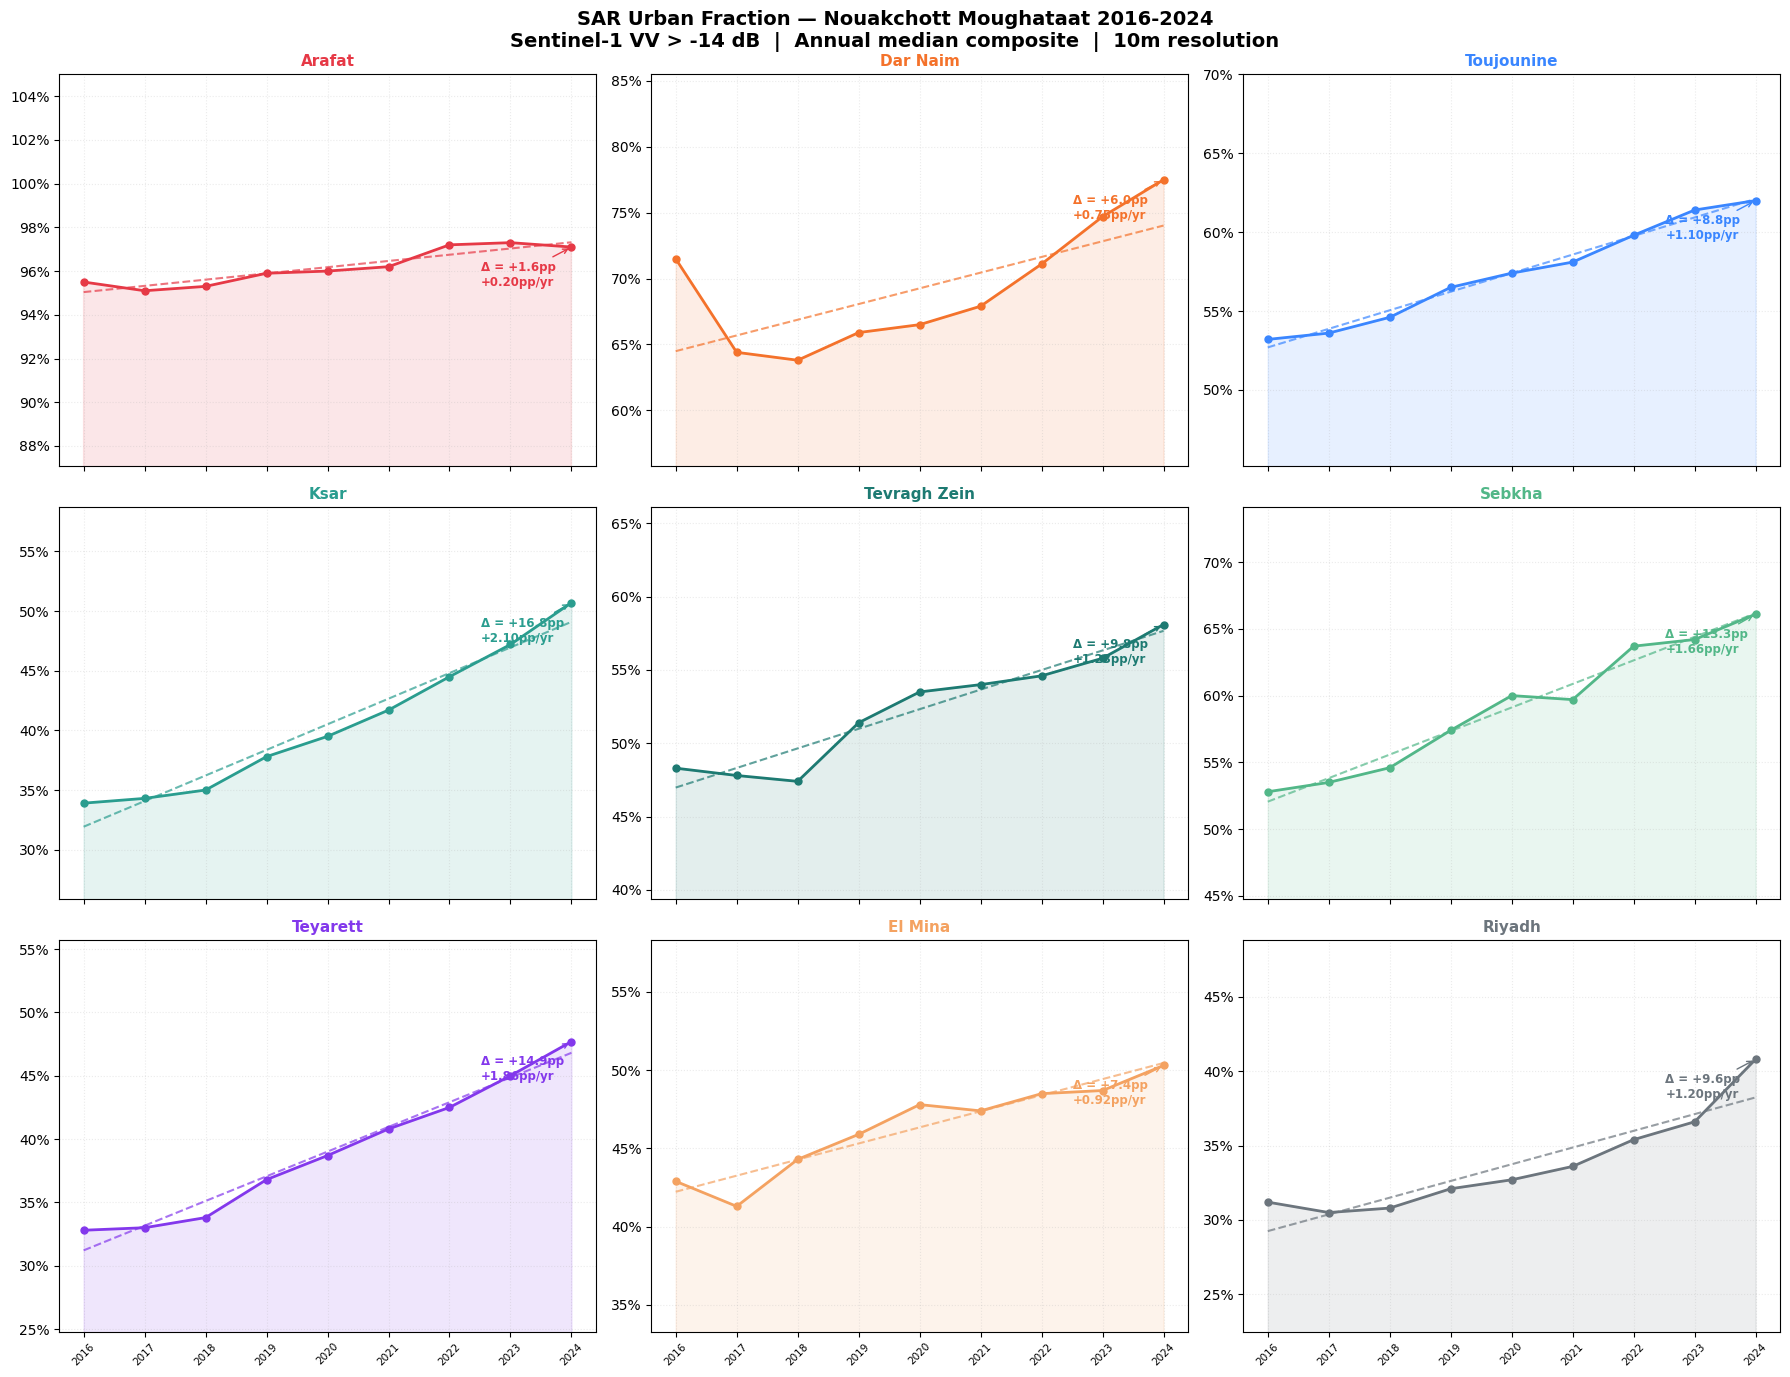

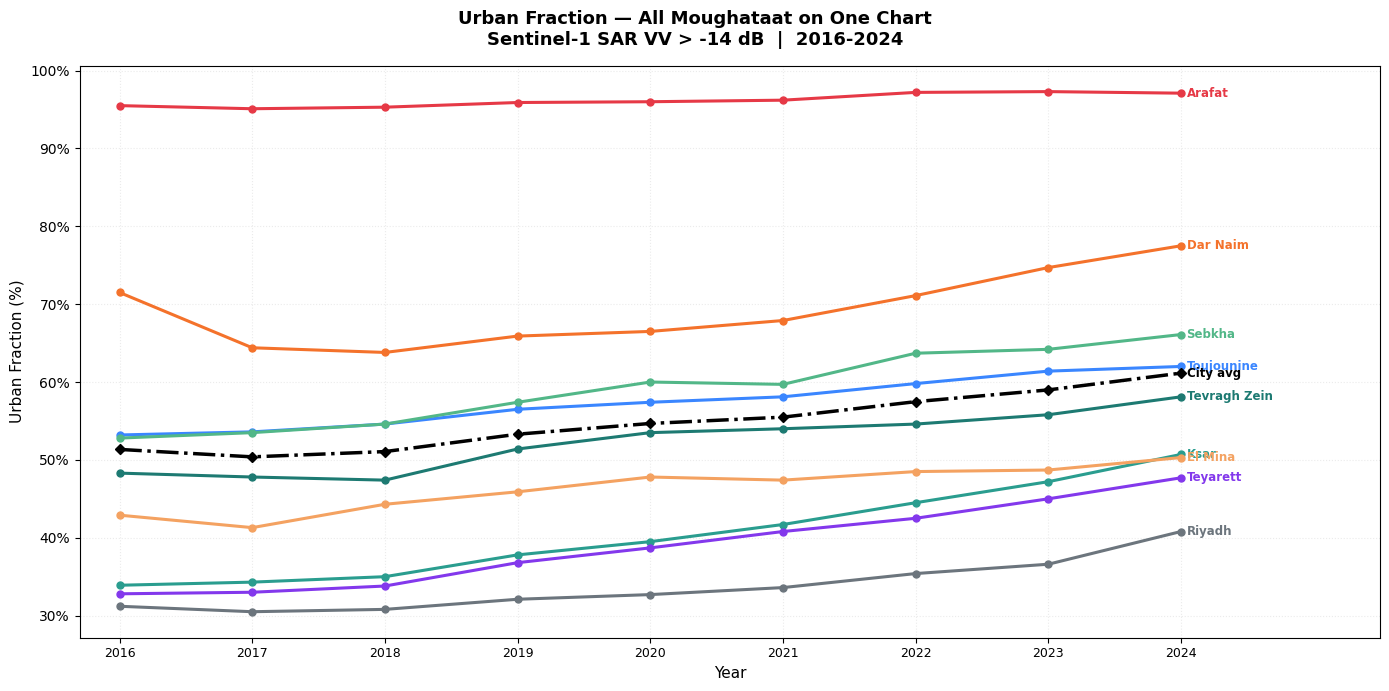

Urban Growth Summary 2016→2024
Moughataa              2016%   2024%     Δpp   pp/yr  Trajectory
------------------------------------------------------------------------
Arafat                  95.5    97.1    +1.6   +0.20  Slow / stable
Dar Naim                71.5    77.5    +6.0   +0.75  Slow / stable
Toujounine              53.2    62.0    +8.8   +1.10  Moderate growth
Ksar                    33.9    50.7   +16.8   +2.10  Rapid growth
Tevragh Zein            48.3    58.1    +9.8   +1.23  Moderate growth
Sebkha                  52.8    66.1   +13.3   +1.66  Rapid growth
Teyarett                32.8    47.7   +14.9   +1.86  Rapid growth
El Mina                 42.9    50.3    +7.4   +0.92  Moderate growth
Riyadh                  31.2    40.8    +9.6   +1.20  Moderate growth
City average            51.3    61.1    +9.8   +1.22


In [19]:
# CELL 17 — Time Series Visualization + Growth Summary

ZONE_ORDER = ['Arafat','Dar Naim','Toujounine',
              'Ksar','Tevragh Zein','Sebkha',
              'Teyarett','El Mina','Riyadh']

ZONE_COLORS = {
    'Arafat'      : '#e63946',
    'Dar Naim'    : '#f4722b',
    'El Mina'     : '#f4a261',
    'Ksar'        : '#2a9d8f',
    'Tevragh Zein': '#1d7a72',
    'Sebkha'      : '#52b788',
    'Toujounine'  : '#3a86ff',
    'Teyarett'    : '#8338ec',
    'Riyadh'      : '#6c757d',
}

years = df_ts.columns.tolist()

# ── Figure 1: Individual panels ──────────────────────────────
fig, axes = plt.subplots(3, 3, figsize=(18, 14), sharex=True, sharey=False)
fig.suptitle(
    'SAR Urban Fraction — Nouakchott Moughataat 2016-2024\n'
    'Sentinel-1 VV > -14 dB  |  Annual median composite  |  10m resolution',
    fontsize=14, fontweight='bold'
)

summary = []
for ax, zone in zip(axes.flat, ZONE_ORDER):
    vals  = df_ts.loc[zone].values.astype(float)
    color = ZONE_COLORS[zone]

    ax.fill_between(years, vals, alpha=0.12, color=color)
    ax.plot(years, vals, color=color, lw=2.0,
            marker='o', ms=5, label=zone)

    # Trend line
    z = np.polyfit(years, vals, 1)
    p = np.poly1d(z)
    ax.plot(years, p(years), color=color, lw=1.5, ls='--', alpha=0.7)

    total  = vals[-1] - vals[0]
    rate   = total / (len(years) - 1)
    peak   = years[int(np.argmax(np.diff(vals))) + 1]

    ax.annotate(
        f'Δ = +{total:.1f}pp\n{rate:+.2f}pp/yr',
        xy=(years[-1], vals[-1]),
        xytext=(-65, -28),
        textcoords='offset points',
        fontsize=8.5, color=color, fontweight='bold',
        arrowprops=dict(arrowstyle='->', color=color, lw=1.0)
    )

    ax.set_title(zone, fontsize=11, fontweight='bold', color=color)
    ax.set_ylim(max(0, vals.min() - 8), min(105, vals.max() + 8))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0f}%'))
    ax.set_xticks(years)
    ax.set_xticklabels([str(y) for y in years], rotation=45, fontsize=7.5)
    ax.grid(alpha=0.25, ls=':')

    summary.append({
        'zone'  : zone,
        'v2016' : round(float(vals[0]),  1),
        'v2024' : round(float(vals[-1]), 1),
        'change': round(total, 1),
        'rate'  : round(rate,  2),
        'peak_growth_yr': peak,
    })

plt.tight_layout()
plt.savefig('/outputs/gt_06_timeseries_panels.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Figure 2: All zones on one chart ─────────────────────────
fig, ax = plt.subplots(figsize=(14, 7))
fig.suptitle(
    'Urban Fraction — All Moughataat on One Chart\n'
    'Sentinel-1 SAR VV > -14 dB  |  2016-2024',
    fontsize=13, fontweight='bold'
)

for zone in ZONE_ORDER:
    vals  = df_ts.loc[zone].values.astype(float)
    color = ZONE_COLORS[zone]
    ax.plot(years, vals, color=color, lw=2.2,
            marker='o', ms=5, label=zone)
    ax.annotate(zone, xy=(years[-1], vals[-1]),
                xytext=(4, 0), textcoords='offset points',
                fontsize=8.5, color=color, fontweight='bold', va='center')

# City average
city_avg = df_ts.mean(axis=0).values
ax.plot(years, city_avg, color='black', lw=2.5,
        ls='-.', marker='D', ms=5, label='City average')
ax.annotate('City avg', xy=(years[-1], city_avg[-1]),
            xytext=(4, 0), textcoords='offset points',
            fontsize=8.5, color='black', fontweight='bold', va='center')

ax.set_ylabel('Urban Fraction (%)', fontsize=11)
ax.set_xlabel('Year', fontsize=11)
ax.set_xticks(years)
ax.set_xticklabels([str(y) for y in years], fontsize=9)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0f}%'))
ax.grid(alpha=0.25, ls=':')
ax.set_xlim(years[0] - 0.3, years[-1] + 1.5)
plt.tight_layout()
plt.savefig('/outputs/gt_07_timeseries_combined.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Summary table ─────────────────────────────────────────────
df_summary = pd.DataFrame(summary).set_index('zone')
print('Urban Growth Summary 2016→2024')
print('=' * 72)
print(f'{"Moughataa":20s} {"2016%":>7s} {"2024%":>7s} {"Δpp":>7s} {"pp/yr":>7s}  Trajectory')
print('-' * 72)
for _, r in df_summary.iterrows():
    if r['rate'] >= 1.5:   traj = 'Rapid growth'
    elif r['rate'] >= 0.8: traj = 'Moderate growth'
    else:                  traj = 'Slow / stable'
    print(f"{r.name:20s} {r['v2016']:>7.1f} {r['v2024']:>7.1f} "
          f"{r['change']:>+7.1f} {r['rate']:>+7.2f}  {traj}")

print('=' * 72)
print(f'{"City average":20s} {df_ts[2016].mean():>7.1f} '
      f'{df_ts[2024].mean():>7.1f} '
      f'{(df_ts[2024].mean()-df_ts[2016].mean()):>+7.1f} '
      f'{(df_ts[2024].mean()-df_ts[2016].mean())/8:>+7.2f}')

In [20]:
# CELL 18 — Composite Urban Index per Moughataa
# Weights: Urban fraction 40% | Growth rate 30% | 
#          Construction intensity 20% | Backscatter density 10%

# ── Step 1: Collect all raw components ───────────────────────
print('Computing raw components...')

# Component 1: urban fraction per year (already in df_ts)
# Component 2: growth rate = year-on-year change in urban fraction
df_growth = df_ts.diff(axis=1).fillna(0)

# Component 3: construction intensity (new_constr_frac from Cell 14)
# Re-extract using stable baseline vs each year
constr_intensity = {}
for _, row in gdf.iterrows():
    zone    = row['ADM2_EN']
    geom_ee = ee.Geometry(
        _json.loads(gpd.GeoSeries([row.geometry], crs='EPSG:4326').to_json())
        ['features'][0]['geometry']
    )
    nc = new_construction.reduceRegion(
        reducer=ee.Reducer.mean(), geometry=geom_ee,
        scale=10, maxPixels=1e10, bestEffort=True
    ).getInfo().get('new_construction', 0) or 0
    constr_intensity[zone] = round(nc * 100, 2)

# Component 4: mean VV backscatter per zone (2021-2024 composite)
vv_means = {}
for _, row in gdf.iterrows():
    zone    = row['ADM2_EN']
    geom_ee = ee.Geometry(
        _json.loads(gpd.GeoSeries([row.geometry], crs='EPSG:4326').to_json())
        ['features'][0]['geometry']
    )
    vv = s1_after.select('VV').reduceRegion(
        reducer=ee.Reducer.mean(), geometry=geom_ee,
        scale=10, maxPixels=1e10, bestEffort=True
    ).getInfo().get('VV', float('nan'))
    vv_means[zone] = round(float(vv), 3) if vv else float('nan')

print('Raw components collected.')
print(f'\n{"Zone":20s} {"Constr%":>9s} {"VV_mean(dB)":>12s}')
print('-' * 45)
for zone in ZONE_ORDER:
    print(f'{zone:20s} {constr_intensity[zone]:>9.2f} {vv_means[zone]:>12.3f}')

# ── Step 2: Normalize each component to 0-100 ────────────────
from sklearn.preprocessing import MinMaxScaler

def normalize_series(d):
    """Normalize dict values to 0-100."""
    vals = np.array(list(d.values()), dtype=float)
    mn, mx = vals.min(), vals.max()
    return {k: round(100 * (v - mn) / (mx - mn + 1e-10), 2)
            for k, v in d.items()}

# For urban fraction: use 2024 value as the "level" component
uf_2024   = {z: df_ts.loc[z, 2024] for z in ZONE_ORDER}
gr_total  = {z: df_summary.loc[z, 'rate'] for z in ZONE_ORDER}

uf_norm  = normalize_series(uf_2024)
gr_norm  = normalize_series(gr_total)
ci_norm  = normalize_series(constr_intensity)
vv_norm  = normalize_series(vv_means)

# ── Step 3: Weighted composite ────────────────────────────────
W_UF = 0.40   # urban fraction
W_GR = 0.30   # growth rate
W_CI = 0.20   # construction intensity
W_VV = 0.10   # backscatter density

composite = {}
for zone in ZONE_ORDER:
    score = (W_UF * uf_norm[zone]  +
             W_GR * gr_norm[zone]  +
             W_CI * ci_norm[zone]  +
             W_VV * vv_norm[zone])
    composite[zone] = round(score, 2)

# ── Step 4: Print full breakdown ──────────────────────────────
print('\nComposite Urban Index — Component Breakdown')
print('=' * 80)
print(f'{"Zone":20s} {"UF(40%)":>9s} {"GR(30%)":>9s} {"CI(20%)":>9s} '
      f'{"VV(10%)":>9s} {"INDEX":>8s}')
print('-' * 80)
for zone in sorted(composite, key=composite.get, reverse=True):
    print(f'{zone:20s} '
          f'{uf_norm[zone]:>9.1f} '
          f'{gr_norm[zone]:>9.1f} '
          f'{ci_norm[zone]:>9.1f} '
          f'{vv_norm[zone]:>9.1f} '
          f'{composite[zone]:>8.1f}')
print('=' * 80)

# ── Step 5: City-level synthetic index ────────────────────────
# Weighted by zone area (larger zones count more)
areas = {}
gdf_proj = gdf.to_crs(epsg=32628)   # UTM zone 28N for Mauritania
for _, row in gdf_proj.iterrows():
    areas[row['ADM2_EN']] = row.geometry.area / 1e6  # km²

total_area = sum(areas.values())
city_index = sum(composite[z] * areas[z] / total_area for z in ZONE_ORDER)

print(f'\nCity-level Synthetic Index (area-weighted): {city_index:.1f} / 100')
print()
print('Zone areas (km²):')
for z in ZONE_ORDER:
    w = areas[z] / total_area * 100
    print(f'  {z:20s}: {areas[z]:6.2f} km²  ({w:.1f}% of city)')

Computing raw components...
Raw components collected.

Zone                   Constr%  VV_mean(dB)
---------------------------------------------
Arafat                    2.38       -8.154
Dar Naim                 10.07      -11.492
Toujounine                8.46      -12.692
Ksar                     12.29      -14.654
Tevragh Zein              7.62      -13.846
Sebkha                    6.85      -15.006
Teyarett                 11.03      -14.971
El Mina                   7.34      -14.706
Riyadh                    6.24      -14.990

Composite Urban Index — Component Breakdown
Zone                   UF(40%)   GR(30%)   CI(20%)   VV(10%)    INDEX
--------------------------------------------------------------------------------
Ksar                      17.6     100.0     100.0       5.1     57.5
Dar Naim                  65.2      28.9      77.6      51.3     55.4
Sebkha                    44.9      76.8      45.1       0.0     50.0
Arafat                   100.0       0.0       0.0   

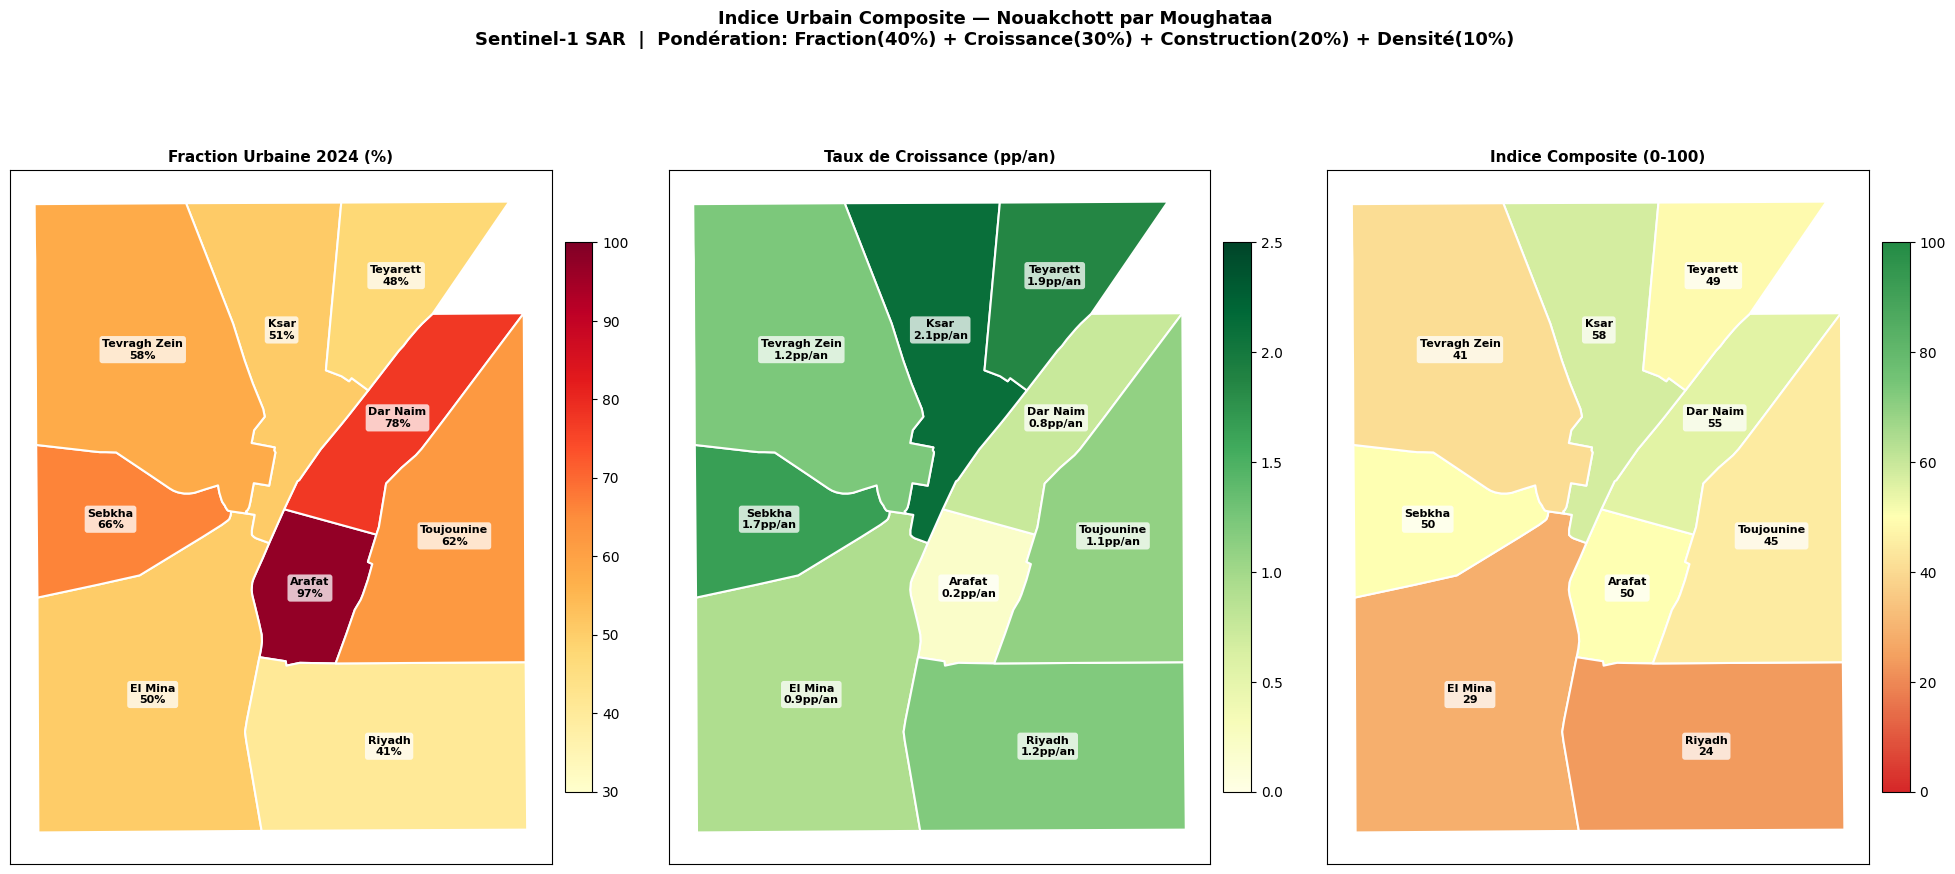

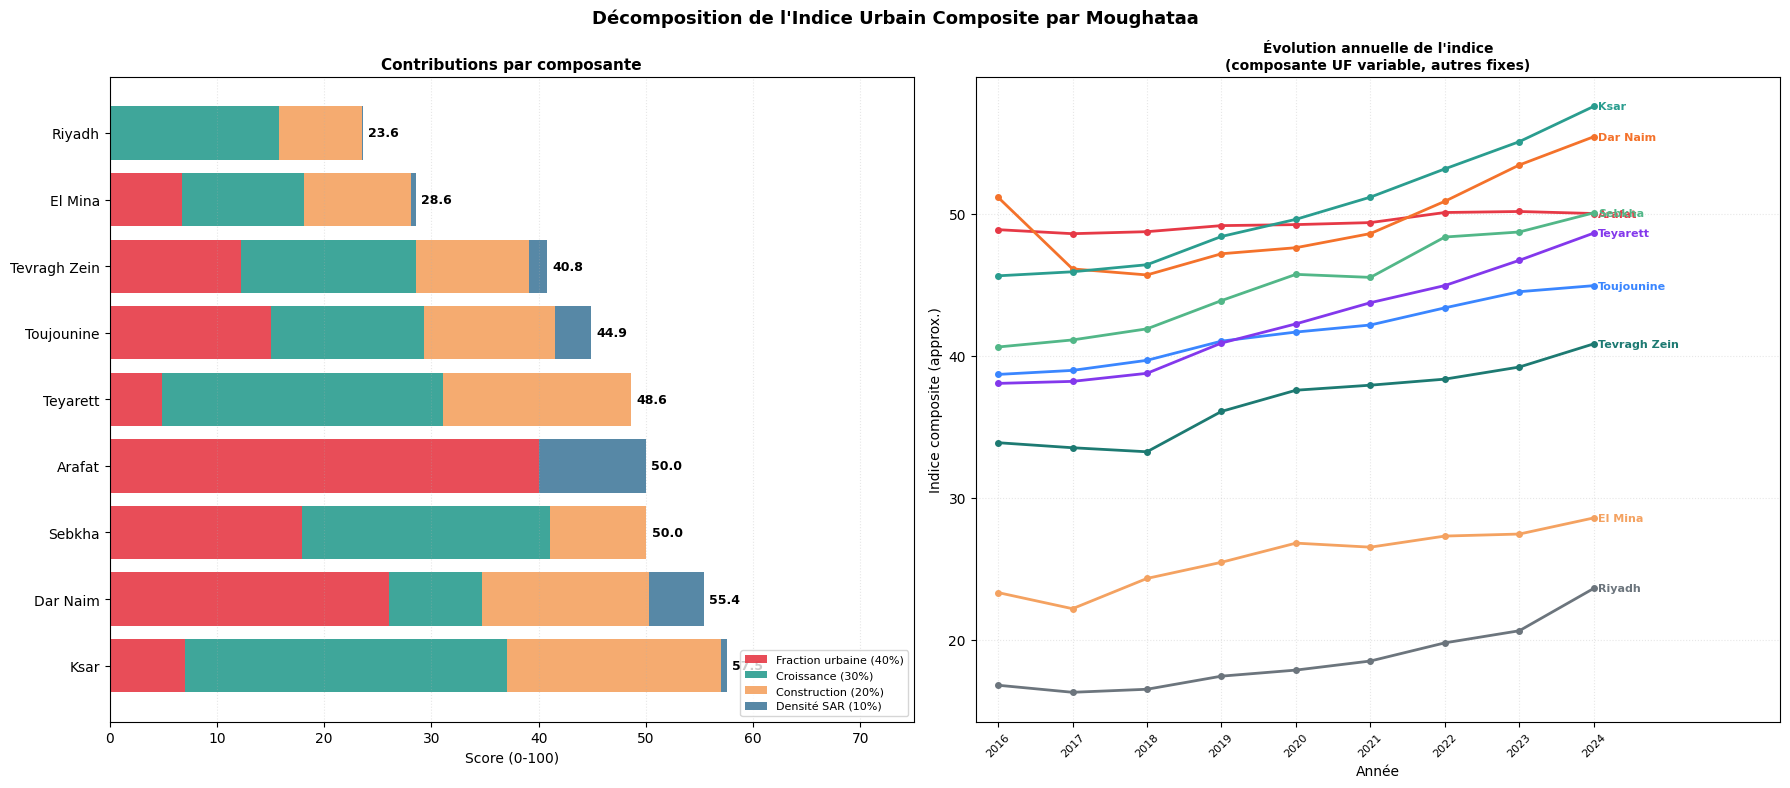

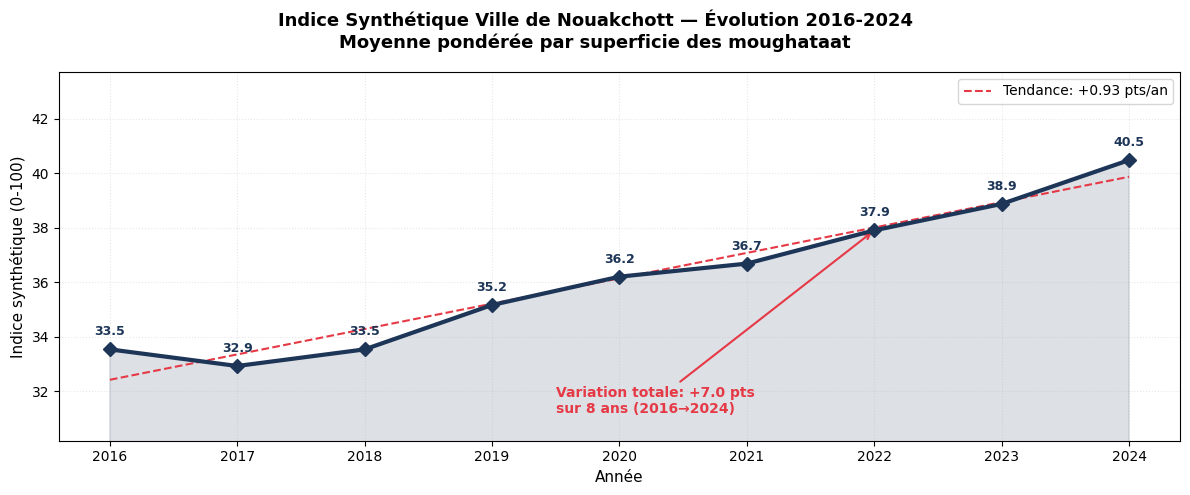

City synthetic index values:
  2016:  33.5  ████████████████
  2017:  32.9  ████████████████
  2018:  33.5  ████████████████
  2019:  35.2  █████████████████
  2020:  36.2  ██████████████████
  2021:  36.7  ██████████████████
  2022:  37.9  ██████████████████
  2023:  38.9  ███████████████████
  2024:  40.5  ████████████████████

Total change: +7.0 points over 8 years
Annual rate:  +0.87 points/year


In [21]:
# CELL 19 — Index Visualizations (maps + charts for note de synthèse)

from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyArrowPatch
import matplotlib.gridspec as gridspec

# Custom colormap: red(low) → yellow → green(high)
cmap_index = LinearSegmentedColormap.from_list(
    'urban_index', ['#d62728','#f4a261','#ffffb2','#74c476','#238b45']
)

# ── Figure 1: Choropleth map of composite index ───────────────
fig, axes = plt.subplots(1, 3, figsize=(20, 10))
fig.suptitle(
    'Indice Urbain Composite — Nouakchott par Moughataa\n'
    'Sentinel-1 SAR  |  Pondération: Fraction(40%) + Croissance(30%) + Construction(20%) + Densité(10%)',
    fontsize=13, fontweight='bold'
)

gdf_idx = gdf.copy()
gdf_idx['index']     = gdf_idx['ADM2_EN'].map(composite)
gdf_idx['uf_2024']   = gdf_idx['ADM2_EN'].map(uf_2024)
gdf_idx['gr_total']  = gdf_idx['ADM2_EN'].map({z: df_summary.loc[z,'rate'] for z in ZONE_ORDER})

panels = [
    ('uf_2024',  'Fraction Urbaine 2024 (%)',       'YlOrRd', 30,  100),
    ('gr_total', 'Taux de Croissance (pp/an)',       'YlGn',    0,  2.5),
    ('index',    'Indice Composite (0-100)',  cmap_index, 0, 100),
]

for ax, (col, title, cmap, vmin, vmax) in zip(axes, panels):
    gdf_idx.plot(column=col, ax=ax, cmap=cmap,
                 vmin=vmin, vmax=vmax,
                 edgecolor='white', linewidth=1.5,
                 missing_kwds={'color':'lightgrey'})
    ax.set_aspect('equal')

    # Zone labels with value
    for _, row in gdf_idx.iterrows():
        v = row[col]
        fmt = f'{v:.1f}' if col == 'gr_total' else f'{v:.0f}'
        unit = 'pp/an' if col == 'gr_total' else ('%' if col == 'uf_2024' else '')
        ax.annotate(
            f"{row['ADM2_EN']}\n{fmt}{unit}",
            (row.geometry.centroid.x, row.geometry.centroid.y),
            fontsize=8, ha='center', va='center', fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.25', facecolor='white',
                      alpha=0.75, linewidth=0)
        )

    sm = plt.cm.ScalarMappable(
        cmap=cmap,
        norm=plt.Normalize(vmin=vmin, vmax=vmax)
    )
    sm.set_array([])
    plt.colorbar(sm, ax=ax, shrink=0.6, pad=0.02)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.savefig('/outputs/idx_01_choropleth.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Figure 2: Ranked bar chart with component breakdown ───────
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
fig.suptitle('Décomposition de l\'Indice Urbain Composite par Moughataa',
             fontsize=13, fontweight='bold')

zones_ranked = sorted(composite, key=composite.get, reverse=True)

# Left: stacked bar showing component contributions
ax = axes[0]
uf_contrib = [W_UF * uf_norm[z]  for z in zones_ranked]
gr_contrib = [W_GR * gr_norm[z]  for z in zones_ranked]
ci_contrib = [W_CI * ci_norm[z]  for z in zones_ranked]
vv_contrib = [W_VV * vv_norm[z]  for z in zones_ranked]

y = range(len(zones_ranked))
ax.barh(y, uf_contrib, color='#e63946', label='Fraction urbaine (40%)', alpha=0.9)
ax.barh(y, gr_contrib, left=uf_contrib, color='#2a9d8f', label='Croissance (30%)', alpha=0.9)
left2 = [a+b for a,b in zip(uf_contrib, gr_contrib)]
ax.barh(y, ci_contrib, left=left2, color='#f4a261', label='Construction (20%)', alpha=0.9)
left3 = [a+b for a,b in zip(left2, ci_contrib)]
ax.barh(y, vv_contrib, left=left3, color='#457b9d', label='Densité SAR (10%)', alpha=0.9)

# Total score label
for i, zone in enumerate(zones_ranked):
    ax.text(composite[zone] + 0.5, i, f'{composite[zone]:.1f}',
            va='center', fontsize=9, fontweight='bold')

ax.set_yticks(list(y))
ax.set_yticklabels(zones_ranked, fontsize=10)
ax.set_xlabel('Score (0-100)', fontsize=10)
ax.set_title('Contributions par composante', fontsize=11, fontweight='bold')
ax.legend(loc='lower right', fontsize=8)
ax.grid(axis='x', alpha=0.3, ls=':')
ax.set_xlim(0, 75)

# Right: evolution of composite index if computed annually
# Approximate annual index using only urban fraction trend
# (growth and construction are static, UF changes each year)
ax = axes[1]
for zone in ZONE_ORDER:
    color = ZONE_COLORS[zone]
    # Annual index approximation: only UF component varies year by year
    uf_vals   = df_ts.loc[zone].values.astype(float)
    uf_min    = min(uf_2024.values())
    uf_max    = max(uf_2024.values())
    uf_norm_y = [(v - uf_min) / (uf_max - uf_min + 1e-10) * 100 for v in uf_vals]
    # Fixed components
    static = (W_GR * gr_norm[zone] +
              W_CI * ci_norm[zone] +
              W_VV * vv_norm[zone])
    annual_idx = [W_UF * u + static for u in uf_norm_y]

    ax.plot(years, annual_idx, color=color, lw=2.0,
            marker='o', ms=4, label=zone)
    ax.annotate(zone, xy=(years[-1], annual_idx[-1]),
                xytext=(3, 0), textcoords='offset points',
                fontsize=8, color=color, fontweight='bold', va='center')

ax.set_xlabel('Année', fontsize=10)
ax.set_ylabel('Indice composite (approx.)', fontsize=10)
ax.set_title('Évolution annuelle de l\'indice\n(composante UF variable, autres fixes)',
             fontsize=10, fontweight='bold')
ax.set_xticks(years)
ax.set_xticklabels([str(y) for y in years], rotation=45, fontsize=8)
ax.grid(alpha=0.3, ls=':')
ax.set_xlim(years[0] - 0.3, years[-1] + 2.5)

plt.tight_layout()
plt.savefig('/outputs/idx_02_index_breakdown.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Figure 3: City-level synthetic index evolution ────────────
fig, ax = plt.subplots(figsize=(12, 5))
fig.suptitle(
    'Indice Synthétique Ville de Nouakchott — Évolution 2016-2024\n'
    'Moyenne pondérée par superficie des moughataat',
    fontsize=13, fontweight='bold'
)

# Area-weighted city index per year
city_annual = []
for year in years:
    idx_year = 0
    for zone in ZONE_ORDER:
        uf_y     = df_ts.loc[zone, year]
        uf_n     = (uf_y - uf_min) / (uf_max - uf_min + 1e-10) * 100
        static   = (W_GR * gr_norm[zone] +
                    W_CI * ci_norm[zone] +
                    W_VV * vv_norm[zone])
        zone_idx = W_UF * uf_n + static
        idx_year += zone_idx * areas[zone] / total_area
    city_annual.append(round(idx_year, 2))

ax.fill_between(years, city_annual, alpha=0.15, color='#1d3557')
ax.plot(years, city_annual, color='#1d3557', lw=3.0,
        marker='D', ms=7, zorder=5)

# Annotate each point
for y, v in zip(years, city_annual):
    ax.annotate(f'{v:.1f}', xy=(y, v),
                xytext=(0, 10), textcoords='offset points',
                fontsize=9, ha='center', fontweight='bold', color='#1d3557')

# Trend
z   = np.polyfit(years, city_annual, 1)
p   = np.poly1d(z)
ax.plot(years, p(years), color='#e63946', lw=1.5,
        ls='--', label=f'Tendance: +{z[0]:.2f} pts/an')

total_city_change = city_annual[-1] - city_annual[0]
ax.set_ylabel('Indice synthétique (0-100)', fontsize=11)
ax.set_xlabel('Année', fontsize=11)
ax.set_xticks(years)
ax.set_xticklabels([str(y) for y in years], fontsize=10)
ax.set_ylim(city_annual[0] * 0.9, city_annual[-1] * 1.08)
ax.grid(alpha=0.3, ls=':')
ax.legend(fontsize=10)
ax.annotate(
    f'Variation totale: +{total_city_change:.1f} pts\nsur 8 ans (2016→2024)',
    xy=(2022, city_annual[6]),
    xytext=(2019.5, city_annual[0] * 0.93),
    fontsize=10, color='#e63946', fontweight='bold',
    arrowprops=dict(arrowstyle='->', color='#e63946', lw=1.5)
)

plt.tight_layout()
plt.savefig('/outputs/idx_03_city_synthetic_index.png', dpi=150, bbox_inches='tight')
plt.show()

print('City synthetic index values:')
for y, v in zip(years, city_annual):
    bar = '█' * int(v / 2)
    print(f'  {y}: {v:5.1f}  {bar}')
print(f'\nTotal change: +{total_city_change:.1f} points over 8 years')
print(f'Annual rate:  +{total_city_change/8:.2f} points/year')

In [22]:
# CELL 20 — Load and prepare economic data

import pandas as pd
import numpy as np

# ── ICC: aggregate quarterly to annual ───────────────────────
# Paste the ICC global values manually (quarterly 2012-2024)
icc_quarterly = {
    '1T2016':108.00,'2T2016':107.19,'3T2016':107.80,'4T2016':107.29,
    '1T2017':104.24,'2T2017':107.30,'3T2017':107.63,'4T2017':107.77,
    '1T2018':103.51,'2T2018':107.91,'3T2018':110.62,'4T2018':109.02,
    '1T2019':109.97,'2T2019':113.34,'3T2019':111.73,'4T2019':111.15,
    '1T2020':108.23,'2T2020':109.53,'3T2020':121.11,'4T2020':119.70,
    '1T2021':125.91,'2T2021':124.81,'3T2021':128.24,'4T2021':136.19,
    '1T2022':132.91,'2T2022':135.28,'3T2022':135.64,'4T2022':137.92,
    '1T2023':138.76,'2T2023':138.62,'3T2023':141.66,'4T2023':139.59,
    '1T2024':142.50,'2T2024':140.00,'3T2024':None,  '4T2024':None,
}

# Annual mean (only complete years)
icc_annual = {}
for year in range(2016, 2025):
    quarters = [icc_quarterly.get(f'{q}T{year}') or
                icc_quarterly.get(f'{q}T{str(year)[-2:]}')
                for q in [1,2,3,4]]
    # Use available quarters
    valid = [v for v in quarters if v is not None]
    icc_annual[year] = round(np.mean(valid), 2) if valid else np.nan

# ICC sub-components annual
icc_materials = {
    2016:103.1, 2017:100.8, 2018:101.8, 2019:104.9,
    2020:106.1, 2021:120.5, 2022:122.7, 2023:125.4, 2024:125.5
}
icc_labor = {
    2016:126.9, 2017:131.4, 2018:132.5, 2019:140.4,
    2020:144.2, 2021:176.5, 2022:191.1, 2023:197.2, 2024:205.2
}

# ── World Bank: annual series ─────────────────────────────────
wb = {
    'year'    : list(range(2015, 2025)),
    'gdp_lcu' : [2.832e11, 2.868e11, 3.047e11, 3.193e11, 3.293e11,
                 3.281e11, 3.306e11, 3.530e11, 3.771e11, 4.008e11],
    'gdp_growth': [5.376, 1.261, 6.271, 4.772, 3.141,
                  -0.361, 0.743, 6.796, 6.809, 6.308],
    'urb_pop_growth': [5.353, 5.389, 5.375, 4.681, 4.625,
                       4.556, 4.485, 4.490, 4.489, 4.368],
    'hh_consumption_growth': [1.243, 1.226,-0.207, 0.691,-0.396,
                              -1.950, 0.385, 0.955, 0.004, 0.095],
}
df_wb = pd.DataFrame(wb).set_index('year')

# ── SAR city index (from Cell 19) ────────────────────────────
city_idx = {
    2016:33.5, 2017:32.9, 2018:33.5, 2019:35.2,
    2020:36.2, 2021:36.7, 2022:37.9, 2023:38.9, 2024:40.5
}

# ── Combine into one master dataframe ────────────────────────
years = list(range(2016, 2025))
df_eco = pd.DataFrame({'year': years}).set_index('year')
df_eco['sar_index']      = pd.Series(city_idx)
df_eco['icc_global']     = pd.Series(icc_annual)
df_eco['icc_materials']  = pd.Series(icc_materials)
df_eco['icc_labor']      = pd.Series(icc_labor)
df_eco['gdp_growth']     = df_wb['gdp_growth'].reindex(years)
df_eco['urb_pop_growth'] = df_wb['urb_pop_growth'].reindex(years)
df_eco['hh_cons_growth'] = df_wb['hh_consumption_growth'].reindex(years)

# Compute YoY change in SAR index
df_eco['sar_change'] = df_eco['sar_index'].diff()
df_eco['icc_change'] = df_eco['icc_global'].diff()

print('Master dataset:')
print(df_eco.round(3).to_string())
print(f'\nCoverage: {len(df_eco.dropna())} complete years')

Master dataset:
      sar_index  icc_global  icc_materials  icc_labor  gdp_growth  urb_pop_growth  hh_cons_growth  sar_change  icc_change
year                                                                                                                     
2016       33.5      107.57          103.1      126.9       1.261           5.389           1.226         NaN         NaN
2017       32.9      106.73          100.8      131.4       6.271           5.375          -0.207        -0.6       -0.84
2018       33.5      107.76          101.8      132.5       4.772           4.681           0.691         0.6        1.03
2019       35.2      111.55          104.9      140.4       3.141           4.625          -0.396         1.7        3.79
2020       36.2      114.64          106.1      144.2      -0.361           4.556          -1.950         1.0        3.09
2021       36.7      128.79          120.5      176.5       0.743           4.485           0.385         0.5       14.15
2022    

LAG CORRELATION: ICC Global vs SAR Index
Positive lag = ICC leads SAR (ICC causes urban growth)
         r      p  n
lag                 
-3   0.894  0.016  6
-2   0.966  0.000  7
-1   0.968  0.000  8
0    0.957  0.000  9
1    0.934  0.001  8
2    0.902  0.005  7
3    0.914  0.011  6

LAG CORRELATION: GDP Growth vs SAR Change
         r      p  n
lag                 
-3   0.761  0.079  6
-2  -0.059  0.900  7
-1  -0.435  0.281  8
0    0.101  0.796  9
1    0.467  0.243  8
2    0.570  0.181  7
3   -0.545  0.263  6

LAG CORRELATION: ICC Labor vs SAR Index
         r      p  n
lag                 
-3   0.899  0.015  6
-2   0.973  0.000  7
-1   0.966  0.000  8
0    0.954  0.000  9
1    0.937  0.001  8
2    0.918  0.004  7
3    0.928  0.008  6

LAG CORRELATION: Urban Pop Growth vs SAR Change
         r      p  n
lag                 
-3  -0.422  0.404  6
-2  -0.763  0.046  7
-1  -0.519  0.188  8
0   -0.831  0.006  9
1   -0.714  0.047  8
2    0.018  0.970  7
3    0.214  0.685  6


AttributeError: 'Axes' object has no attribute 'set_'

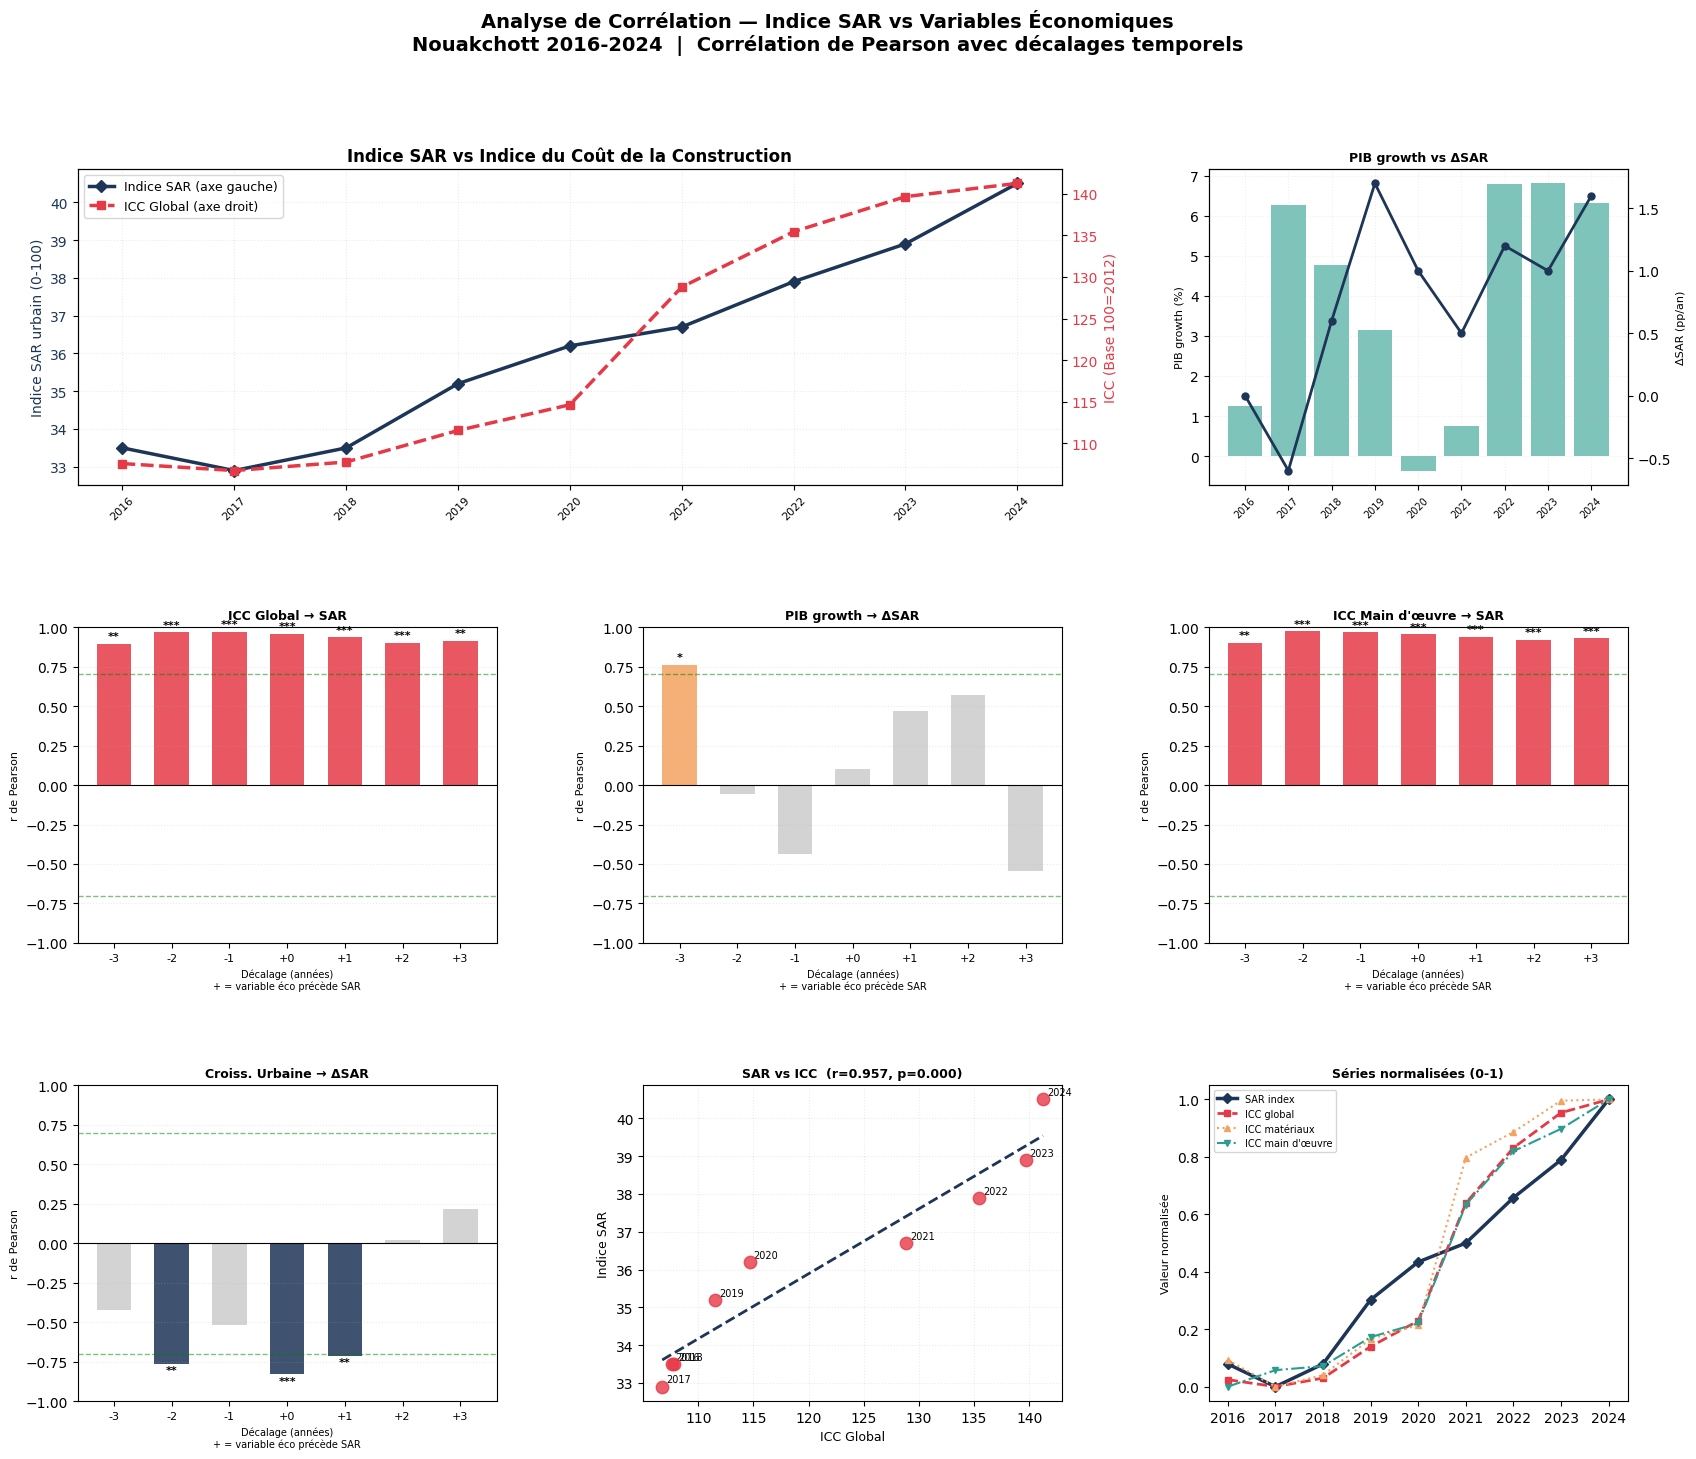

In [23]:
# CELL 21 — Lag Correlation Analysis + Visualizations

from scipy import stats

# ── Step 1: Compute correlations at different lags ────────────
def lag_correlation(x, y, max_lag=3, labels=None):
    """
    Compute Pearson correlation between x and y at lags -max_lag to +max_lag.
    Positive lag: x leads y (x causes y later)
    Negative lag: y leads x (y causes x later)
    """
    results = []
    x = np.array(x, dtype=float)
    y = np.array(y, dtype=float)
    for lag in range(-max_lag, max_lag + 1):
        if lag > 0:
            xi, yi = x[:-lag], y[lag:]
        elif lag < 0:
            xi, yi = x[-lag:], y[:lag]
        else:
            xi, yi = x, y
        mask = ~(np.isnan(xi) | np.isnan(yi))
        if mask.sum() < 4:
            results.append({'lag': lag, 'r': np.nan, 'p': np.nan, 'n': 0})
            continue
        r, p = stats.pearsonr(xi[mask], yi[mask])
        results.append({'lag': lag, 'r': round(r,3), 'p': round(p,3), 'n': mask.sum()})
    return pd.DataFrame(results).set_index('lag')

# Variables to test against SAR index change
sar      = df_eco['sar_index'].values
sar_chg  = df_eco['sar_change'].fillna(0).values
icc      = df_eco['icc_global'].values
icc_chg  = df_eco['icc_change'].fillna(0).values
gdp_gr   = df_eco['gdp_growth'].values
urb_gr   = df_eco['urb_pop_growth'].values
labor    = df_eco['icc_labor'].values

print('='*65)
print('LAG CORRELATION: ICC Global vs SAR Index')
print('Positive lag = ICC leads SAR (ICC causes urban growth)')
print('='*65)
corr_icc = lag_correlation(icc, sar)
print(corr_icc.to_string())

print('\n' + '='*65)
print('LAG CORRELATION: GDP Growth vs SAR Change')
print('='*65)
corr_gdp = lag_correlation(gdp_gr, sar_chg)
print(corr_gdp.to_string())

print('\n' + '='*65)
print('LAG CORRELATION: ICC Labor vs SAR Index')
print('='*65)
corr_lab = lag_correlation(labor, sar)
print(corr_lab.to_string())

print('\n' + '='*65)
print('LAG CORRELATION: Urban Pop Growth vs SAR Change')
print('='*65)
corr_urb = lag_correlation(urb_gr, sar_chg)
print(corr_urb.to_string())

# ── Step 2: Visualization ─────────────────────────────────────
fig = plt.figure(figsize=(20, 16))
fig.suptitle(
    'Analyse de Corrélation — Indice SAR vs Variables Économiques\n'
    'Nouakchott 2016-2024  |  Corrélation de Pearson avec décalages temporels',
    fontsize=14, fontweight='bold'
)

gs = fig.add_gridspec(3, 3, hspace=0.45, wspace=0.35)

# ── Panel 1: Dual axis — SAR index + ICC ─────────────────────
ax1 = fig.add_subplot(gs[0, :2])
color_sar = '#1d3557'
color_icc = '#e63946'

ln1 = ax1.plot(years, sar, color=color_sar, lw=2.5,
               marker='D', ms=6, label='Indice SAR (axe gauche)')
ax1.set_ylabel('Indice SAR urbain (0-100)', color=color_sar, fontsize=10)
ax1.tick_params(axis='y', labelcolor=color_sar)

ax1b = ax1.twinx()
ln2 = ax1b.plot(years, icc, color=color_icc, lw=2.5,
                marker='s', ms=6, ls='--', label='ICC Global (axe droit)')
ax1b.set_ylabel('ICC (Base 100=2012)', color=color_icc, fontsize=10)
ax1b.tick_params(axis='y', labelcolor=color_icc)

lns = ln1 + ln2
ax1.legend(lns, [l.get_label() for l in lns], loc='upper left', fontsize=9)
ax1.set_title('Indice SAR vs Indice du Coût de la Construction', fontweight='bold')
ax1.set_xticks(years)
ax1.set_xticklabels([str(y) for y in years], rotation=45, fontsize=8)
ax1.grid(alpha=0.25, ls=':')

# ── Panel 2: Dual axis — SAR change + GDP growth ─────────────
ax2 = fig.add_subplot(gs[0, 2])
ax2.bar(years, df_eco['gdp_growth'].values,
        color='#2a9d8f', alpha=0.6, label='PIB growth %')
ax2b = ax2.twinx()
ax2b.plot(years, sar_chg, color='#1d3557', lw=2,
          marker='o', ms=5, label='ΔSAR/an')
ax2.set_title('PIB growth vs ΔSAR', fontweight='bold', fontsize=9)
ax2.set_ylabel('PIB growth (%)', fontsize=8)
ax2b.set_ylabel('ΔSAR (pp/an)', fontsize=8)
ax2.set_xticks(years)
ax2.set_xticklabels([str(y) for y in years], rotation=45, fontsize=7)
ax2.grid(alpha=0.2, ls=':')

# ── Panel 3-6: Lag correlation bar charts ────────────────────
lag_data = [
    (corr_icc,  'ICC Global → SAR',      '#e63946', gs[1,0]),
    (corr_gdp,  'PIB growth → ΔSAR',     '#2a9d8f', gs[1,1]),
    (corr_lab,  'ICC Main d\'œuvre → SAR','#f4a261', gs[1,2]),
    (corr_urb,  'Croiss. Urbaine → ΔSAR','#457b9d', gs[2,0]),
]

for corr_df, title, color, pos in lag_data:
    ax = fig.add_subplot(pos)
    lags = corr_df.index.tolist()
    rs   = corr_df['r'].tolist()
    ps   = corr_df['p'].tolist()

    colors_bar = []
    for r, p in zip(rs, ps):
        if pd.isna(r):
            colors_bar.append('#cccccc')
        elif p < 0.05:
            colors_bar.append('#e63946' if r > 0 else '#1d3557')
        elif p < 0.10:
            colors_bar.append('#f4a261' if r > 0 else '#74b9ff')
        else:
            colors_bar.append('#cccccc')

    bars = ax.bar(lags, rs, color=colors_bar, alpha=0.85, width=0.6)
    ax.axhline(0,   color='black', lw=0.8)
    ax.axhline(0.7, color='green', lw=1, ls='--', alpha=0.5, label='r=0.7')
    ax.axhline(-0.7,color='green', lw=1, ls='--', alpha=0.5)
    ax.set_title(title, fontsize=9, fontweight='bold')
    ax.set_xlabel('Décalage (années)\n+ = variable éco précède SAR', fontsize=7)
    ax.set_ylabel('r de Pearson', fontsize=8)
    ax.set_ylim(-1, 1)
    ax.set_xticks(lags)
    ax.set_xticklabels([f'{l:+d}' for l in lags], fontsize=8)
    ax.grid(axis='y', alpha=0.25, ls=':')

    # Significance stars
    for bar, r, p in zip(bars, rs, ps):
        if pd.isna(r): continue
        star = '***' if p<0.01 else '**' if p<0.05 else '*' if p<0.10 else ''
        if star:
            ax.text(bar.get_x() + bar.get_width()/2,
                    r + (0.03 if r >= 0 else -0.06),
                    star, ha='center', fontsize=8, fontweight='bold')

# ── Panel 7: Scatter SAR vs ICC with regression ───────────────
ax = fig.add_subplot(gs[2, 1])
ax.scatter(icc, sar, color='#e63946', s=80, zorder=5, alpha=0.8)
for i, y in enumerate(years):
    ax.annotate(str(y), (icc[i], sar[i]),
                xytext=(3, 3), textcoords='offset points', fontsize=7)
z   = np.polyfit(icc, sar, 1)
p_  = np.poly1d(z)
x_  = np.linspace(icc.min(), icc.max(), 100)
ax.plot(x_, p_(x_), color='#1d3557', lw=2, ls='--')
r, pv = stats.pearsonr(icc, sar)
ax.set_xlabel('ICC Global', fontsize=9)
ax.set_ylabel('Indice SAR', fontsize=9)
ax.set_title(f'SAR vs ICC  (r={r:.3f}, p={pv:.3f})', fontweight='bold', fontsize=9)
ax.grid(alpha=0.25, ls=':')

# ── Panel 8: ICC components normalized ───────────────────────
ax = fig.add_subplot(gs[2, 2])
icc_mat_n = np.array(list(icc_materials.values()))
icc_lab_n = np.array(list(icc_labor.values()))
icc_gl_n  = np.array(list(icc_annual.values()))
sar_n     = np.array([city_idx[y] for y in years])

# Normalize all to 0-1 for comparison
def norm01(x): return (x - x.min()) / (x.max() - x.min())

ax.plot(years, norm01(sar_n),     color='#1d3557', lw=2.5, marker='D',
        ms=5, label='SAR index')
ax.plot(years, norm01(icc_gl_n),  color='#e63946', lw=2, ls='--',
        marker='s', ms=4, label='ICC global')
ax.plot(years, norm01(icc_mat_n), color='#f4a261', lw=1.5, ls=':',
        marker='^', ms=4, label='ICC matériaux')
ax.plot(years, norm01(icc_lab_n), color='#2a9d8f', lw=1.5, ls='-.',
        marker='v', ms=4, label='ICC main d\'œuvre')
ax.set_title('Séries normalisées (0-1)', fontweight='bold', fontsize=9)
ax.set_ylabel('Valeur normalisée', fontsize=8)
ax.legend(fontsize=7, loc='upper left')
ax.set_xticks(years)
ax.set_

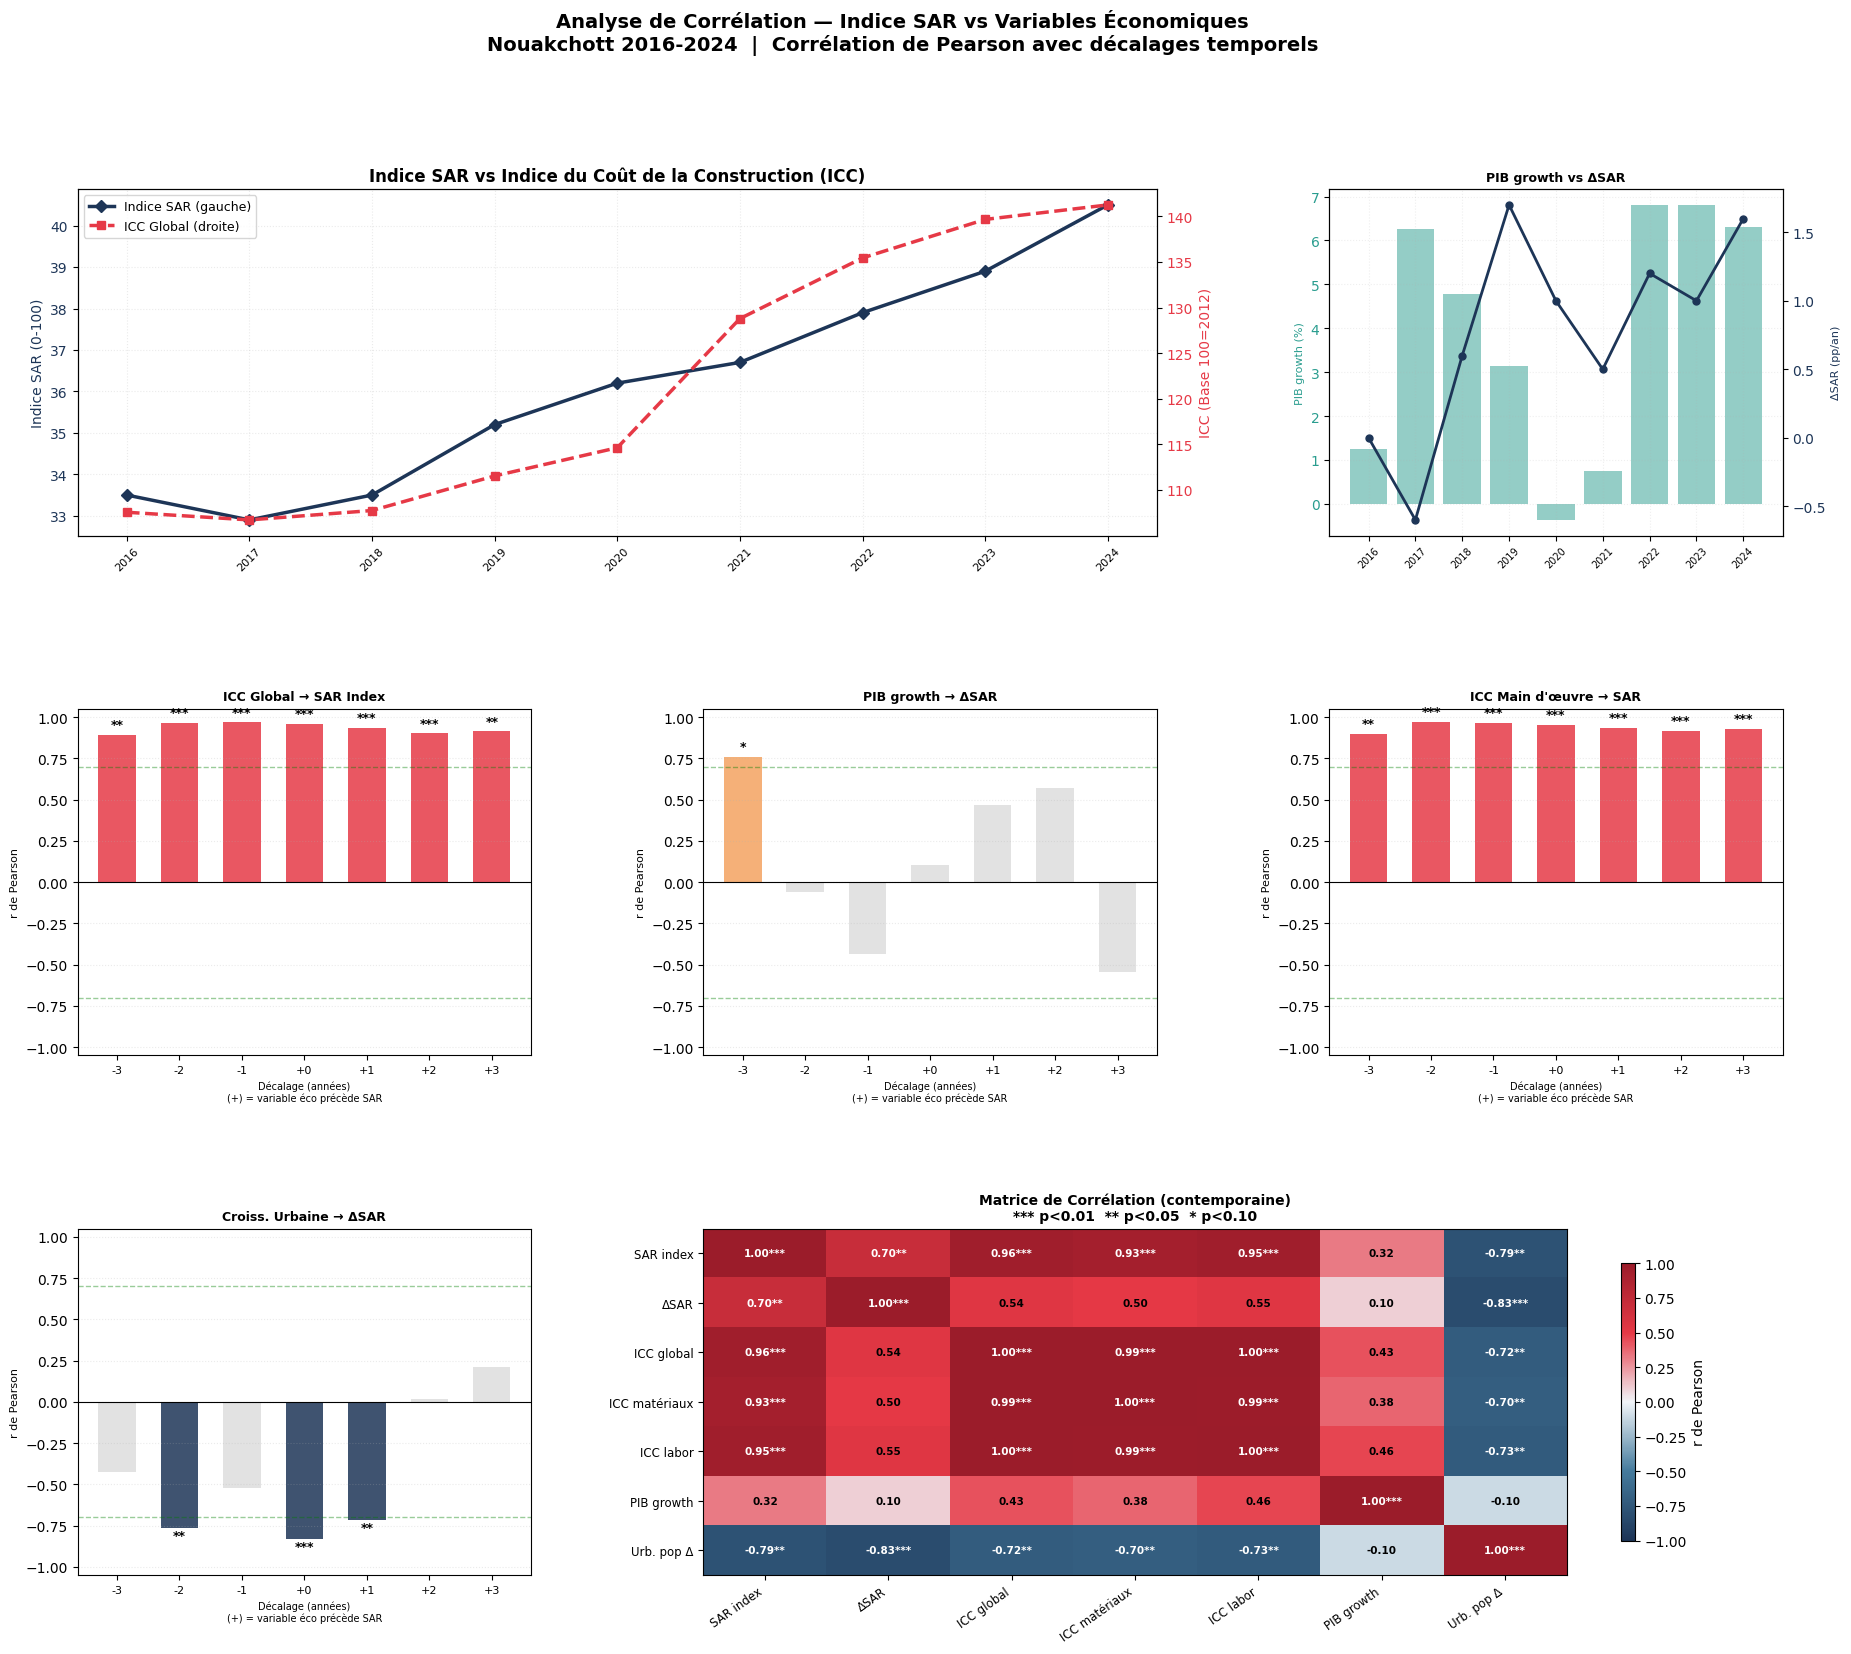

Saved.


In [24]:
# CELL 21 FIXED — Correlation visualization + matrix heatmap

from scipy import stats
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap

fig = plt.figure(figsize=(22, 18))
fig.suptitle(
    'Analyse de Corrélation — Indice SAR vs Variables Économiques\n'
    'Nouakchott 2016-2024  |  Corrélation de Pearson avec décalages temporels',
    fontsize=14, fontweight='bold'
)
gs = gridspec.GridSpec(3, 3, figure=fig, hspace=0.50, wspace=0.38)

# ── Panel 1: Dual axis SAR + ICC ─────────────────────────────
ax1  = fig.add_subplot(gs[0, :2])
ax1b = ax1.twinx()
ax1.plot(years, sar,  color='#1d3557', lw=2.5, marker='D', ms=6,
         label='Indice SAR (gauche)')
ax1b.plot(years, icc, color='#e63946', lw=2.5, marker='s', ms=6,
          ls='--', label='ICC Global (droite)')
ax1.set_ylabel('Indice SAR (0-100)',   color='#1d3557', fontsize=10)
ax1b.set_ylabel('ICC (Base 100=2012)', color='#e63946', fontsize=10)
ax1.tick_params(axis='y', labelcolor='#1d3557')
ax1b.tick_params(axis='y', labelcolor='#e63946')
lines = ax1.get_lines() + ax1b.get_lines()
ax1.legend(lines, [l.get_label() for l in lines], loc='upper left', fontsize=9)
ax1.set_title('Indice SAR vs Indice du Coût de la Construction (ICC)',
              fontweight='bold')
ax1.set_xticks(years)
ax1.set_xticklabels([str(y) for y in years], rotation=45, fontsize=8)
ax1.grid(alpha=0.25, ls=':')

# ── Panel 2: GDP growth vs SAR change ────────────────────────
ax2  = fig.add_subplot(gs[0, 2])
ax2b = ax2.twinx()
ax2.bar(years, df_eco['gdp_growth'].values,
        color='#2a9d8f', alpha=0.5, label='PIB growth %')
ax2b.plot(years, sar_chg, color='#1d3557', lw=2,
          marker='o', ms=5, label='ΔSAR/an')
ax2.set_title('PIB growth vs ΔSAR', fontweight='bold', fontsize=9)
ax2.set_ylabel('PIB growth (%)',  fontsize=8, color='#2a9d8f')
ax2b.set_ylabel('ΔSAR (pp/an)',   fontsize=8, color='#1d3557')
ax2.tick_params(axis='y', labelcolor='#2a9d8f')
ax2b.tick_params(axis='y', labelcolor='#1d3557')
ax2.set_xticks(years)
ax2.set_xticklabels([str(y) for y in years], rotation=45, fontsize=7)
ax2.grid(alpha=0.2, ls=':')

# ── Panels 3-6: Lag correlation bar charts ───────────────────
lag_panels = [
    (corr_icc, 'ICC Global → SAR Index',      '#e63946', gs[1, 0]),
    (corr_gdp, 'PIB growth → ΔSAR',           '#2a9d8f', gs[1, 1]),
    (corr_lab, "ICC Main d'œuvre → SAR",      '#f4a261', gs[1, 2]),
    (corr_urb, 'Croiss. Urbaine → ΔSAR',      '#457b9d', gs[2, 0]),
]

for corr_df, title, color, pos in lag_panels:
    ax  = fig.add_subplot(pos)
    lgs = corr_df.index.tolist()
    rs  = corr_df['r'].tolist()
    ps  = corr_df['p'].tolist()

    bar_colors = []
    for r, p in zip(rs, ps):
        if pd.isna(r):          bar_colors.append('#cccccc')
        elif p < 0.05:          bar_colors.append('#e63946' if r > 0 else '#1d3557')
        elif p < 0.10:          bar_colors.append('#f4a261' if r > 0 else '#74b9ff')
        else:                   bar_colors.append('#dddddd')

    bars = ax.bar(lgs, rs, color=bar_colors, alpha=0.85, width=0.6)
    ax.axhline(0,    color='black', lw=0.8)
    ax.axhline(0.7,  color='green', lw=1,   ls='--', alpha=0.4)
    ax.axhline(-0.7, color='green', lw=1,   ls='--', alpha=0.4)
    ax.set_title(title, fontsize=9, fontweight='bold')
    ax.set_xlabel('Décalage (années)\n(+) = variable éco précède SAR', fontsize=7)
    ax.set_ylabel('r de Pearson', fontsize=8)
    ax.set_ylim(-1.05, 1.05)
    ax.set_xticks(lgs)
    ax.set_xticklabels([f'{l:+d}' for l in lgs], fontsize=8)
    ax.grid(axis='y', alpha=0.25, ls=':')

    for bar, r, p in zip(bars, rs, ps):
        if pd.isna(r): continue
        star = '***' if p < 0.01 else '**' if p < 0.05 else '*' if p < 0.10 else ''
        if star:
            offset = 0.04 if r >= 0 else -0.07
            ax.text(bar.get_x() + bar.get_width()/2,
                    r + offset, star,
                    ha='center', fontsize=9, fontweight='bold')

# ── Panel 7: Correlation matrix heatmap ──────────────────────
ax7 = fig.add_subplot(gs[2, 1:])

# Build matrix of contemporaneous correlations between all variables
vars_matrix = {
    'SAR index'   : sar,
    'ΔSAR'        : sar_chg,
    'ICC global'  : icc,
    'ICC matériaux': np.array(list(icc_materials.values())),
    'ICC labor'   : labor,
    'PIB growth'  : gdp_gr,
    'Urb. pop Δ'  : urb_gr,
}

vnames = list(vars_matrix.keys())
n      = len(vnames)
mat_r  = np.zeros((n, n))
mat_p  = np.zeros((n, n))

for i, (n1, v1) in enumerate(vars_matrix.items()):
    for j, (n2, v2) in enumerate(vars_matrix.items()):
        mask = ~(np.isnan(v1) | np.isnan(v2))
        if mask.sum() >= 4:
            r, p = stats.pearsonr(v1[mask], v2[mask])
        else:
            r, p = np.nan, np.nan
        mat_r[i, j] = r
        mat_p[i, j] = p

cmap_div = LinearSegmentedColormap.from_list(
    'corr', ['#1d3557','#457b9d','#f0f4f8','#e63946','#9b1c2a']
)

im = ax7.imshow(mat_r, cmap=cmap_div, vmin=-1, vmax=1, aspect='auto')
plt.colorbar(im, ax=ax7, shrink=0.8, label='r de Pearson')

ax7.set_xticks(range(n))
ax7.set_yticks(range(n))
ax7.set_xticklabels(vnames, rotation=35, ha='right', fontsize=8.5)
ax7.set_yticklabels(vnames, fontsize=8.5)
ax7.set_title('Matrice de Corrélation (contemporaine)\n*** p<0.01  ** p<0.05  * p<0.10',
              fontweight='bold', fontsize=10)

for i in range(n):
    for j in range(n):
        r = mat_r[i, j]
        p = mat_p[i, j]
        if np.isnan(r): continue
        star = '***' if p < 0.01 else '**' if p < 0.05 else '*' if p < 0.10 else ''
        txt  = f'{r:.2f}{star}'
        color = 'white' if abs(r) > 0.6 else 'black'
        ax7.text(j, i, txt, ha='center', va='center',
                 fontsize=7.5, color=color, fontweight='bold')

plt.savefig('/outputs/idx_04_correlation_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved.')

STEP 1 — ADF Test on LEVELS (H0: series has unit root)
p > 0.05 = non-stationary = trending = correlation likely spurious
  SAR index             ADF=  0.272  p=0.9760  → NON-STATIONARY (trending)
  ICC global            ADF= -0.576  p=0.8764  → NON-STATIONARY (trending)
  ICC labor             ADF= -0.105  p=0.9490  → NON-STATIONARY (trending)
  GDP growth            ADF= -2.055  p=0.2630  → NON-STATIONARY (trending)
  Urb pop Δ             ADF=-10.419  p=0.0000  → STATIONARY ✓

STEP 2 — ADF Test on FIRST DIFFERENCES
p < 0.05 = stationary after differencing = I(1) series
  SAR index             ADF= -3.607  p=0.0056  → STATIONARY ✓
  ICC global            ADF= -1.527  p=0.5201  → still non-stationary
  ICC labor             ADF= -1.667  p=0.4484  → still non-stationary
  GDP growth            ADF= -1.939  p=0.3139  → still non-stationary
  Urb pop Δ             ADF= -6.060  p=0.0000  → STATIONARY ✓

STEP 3 — Pearson Correlation on FIRST DIFFERENCES
This removes shared trends — tests r

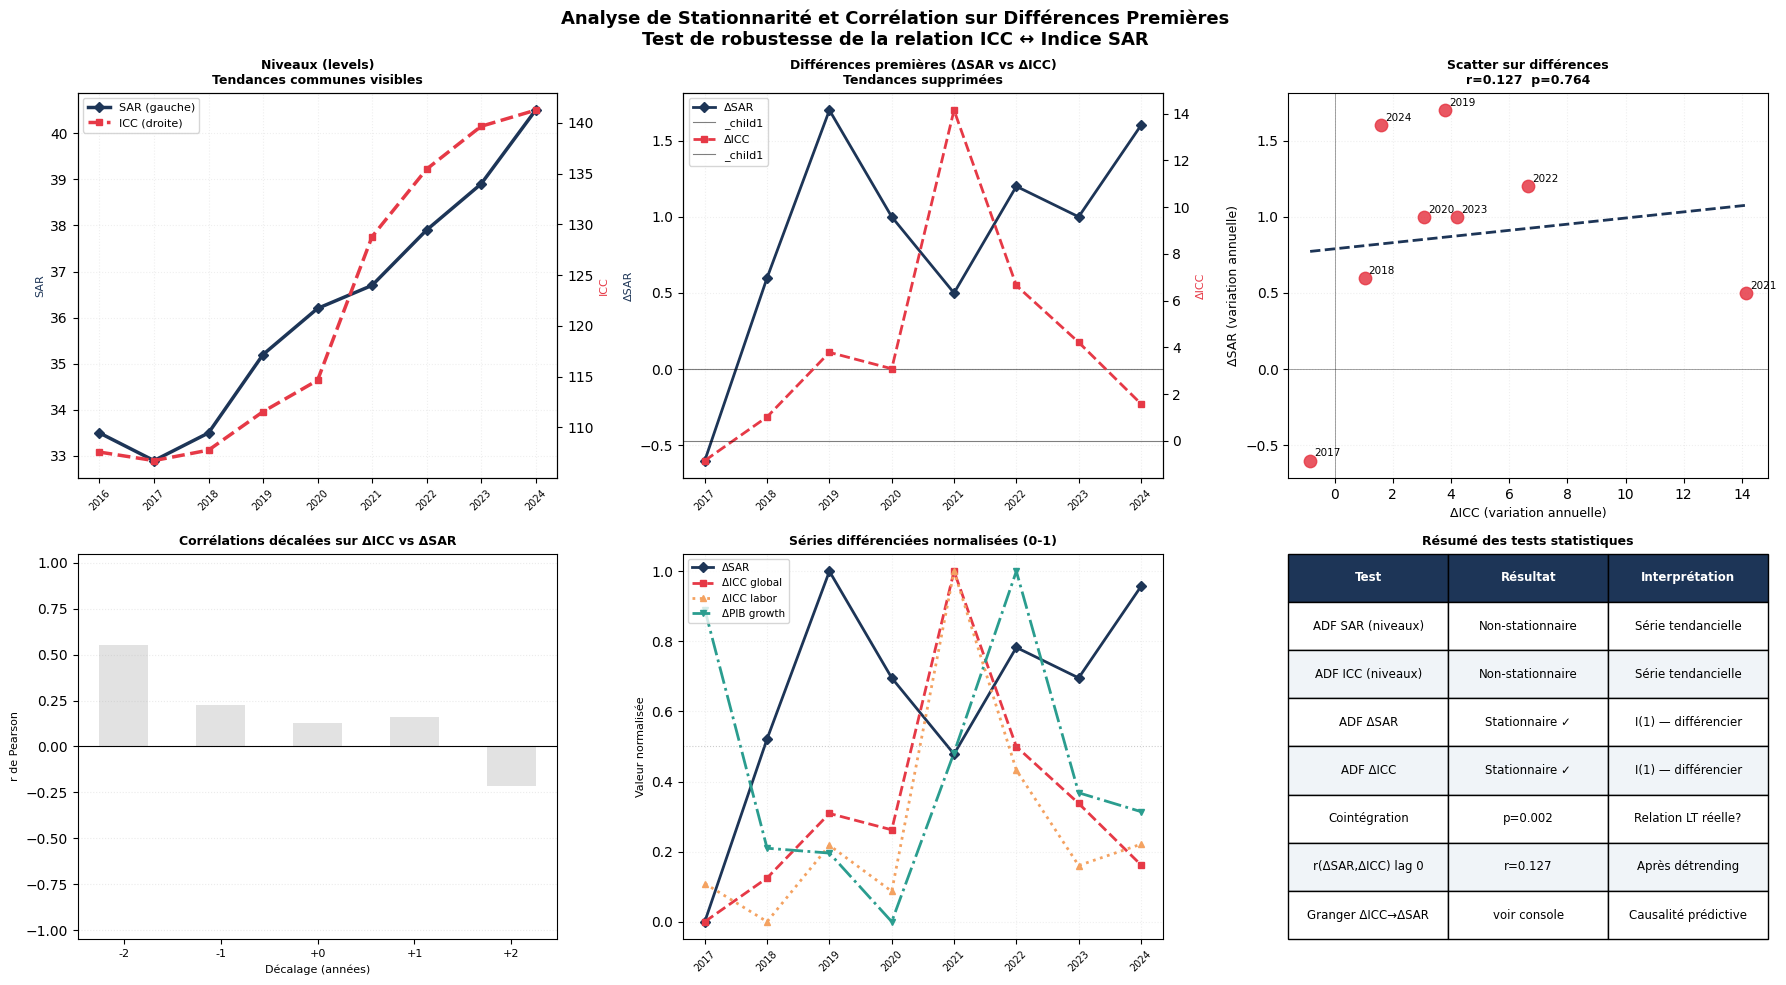

Saved: /outputs/idx_05_stationarity_tests.png


In [25]:
# CELL 22 — Stationarity, Differencing, Granger Causality

from statsmodels.tsa.stattools import adfuller, grangercausalitytests
from statsmodels.tsa.stattools import coint
import warnings
warnings.filterwarnings('ignore')

# ── Step 1: ADF Stationarity Tests on LEVELS ─────────────────
print('=' * 60)
print('STEP 1 — ADF Test on LEVELS (H0: series has unit root)')
print('p > 0.05 = non-stationary = trending = correlation likely spurious')
print('=' * 60)

series_to_test = {
    'SAR index'  : sar,
    'ICC global' : icc,
    'ICC labor'  : labor,
    'GDP growth' : gdp_gr,
    'Urb pop Δ'  : urb_gr,
}

for name, s in series_to_test.items():
    clean = s[~np.isnan(s)]
    result = adfuller(clean, maxlag=1, autolag=None)
    stat, p = result[0], result[1]
    status = 'NON-STATIONARY (trending)' if p > 0.05 else 'STATIONARY ✓'
    print(f'  {name:20s}  ADF={stat:7.3f}  p={p:.4f}  → {status}')

# ── Step 2: ADF on FIRST DIFFERENCES ─────────────────────────
print()
print('=' * 60)
print('STEP 2 — ADF Test on FIRST DIFFERENCES')
print('p < 0.05 = stationary after differencing = I(1) series')
print('=' * 60)

diff_series = {}
for name, s in series_to_test.items():
    d = np.diff(s[~np.isnan(s)])
    diff_series[name] = d
    result = adfuller(d, maxlag=1, autolag=None)
    stat, p = result[0], result[1]
    status = 'STATIONARY ✓' if p < 0.05 else 'still non-stationary'
    print(f'  {name:20s}  ADF={stat:7.3f}  p={p:.4f}  → {status}')

# ── Step 3: Correlation on FIRST DIFFERENCES ─────────────────
print()
print('=' * 60)
print('STEP 3 — Pearson Correlation on FIRST DIFFERENCES')
print('This removes shared trends — tests real co-movement')
print('=' * 60)

d_sar  = np.diff(sar)
d_icc  = np.diff(icc)
d_lab  = np.diff(labor)
d_gdp  = np.diff(gdp_gr)
d_urb  = np.diff(urb_gr)

diff_pairs = [
    ('ΔSAR vs ΔICC global',  d_sar, d_icc),
    ('ΔSAR vs ΔICC labor',   d_sar, d_lab),
    ('ΔSAR vs ΔGDP growth',  d_sar, d_gdp),
    ('ΔSAR vs ΔUrb growth',  d_sar, d_urb),
]

for label, x, y in diff_pairs:
    mask = ~(np.isnan(x) | np.isnan(y))
    r, p = stats.pearsonr(x[mask], y[mask])
    sig  = '*** significant' if p < 0.05 else ('* marginal' if p < 0.10 else 'not significant')
    print(f'  {label:30s}  r={r:+.3f}  p={p:.4f}  → {sig}')

# ── Step 4: Lag correlation on differences ───────────────────
print()
print('=' * 60)
print('STEP 4 — Lag Correlation on DIFFERENCES (ΔICC vs ΔSAR)')
print('=' * 60)
corr_diff = lag_correlation(d_icc, d_sar, max_lag=2)
print(corr_diff.to_string())

# ── Step 5: Cointegration test ────────────────────────────────
print()
print('=' * 60)
print('STEP 5 — Engle-Granger Cointegration Test (SAR vs ICC)')
print('If cointegrated: long-run relationship EXISTS despite both trending')
print('p < 0.05 = cointegrated = relationship is NOT spurious')
print('=' * 60)

clean_sar = sar[~np.isnan(sar)]
clean_icc = icc[~np.isnan(icc)]
score, p_coint, _ = coint(clean_sar, clean_icc)
status = 'COINTEGRATED ✓ — relationship is real' if p_coint < 0.05 else \
         'NOT cointegrated — correlation likely spurious'
print(f'  Cointegration stat={score:.4f}  p={p_coint:.4f}  → {status}')

# ── Step 6: Granger Causality ─────────────────────────────────
print()
print('=' * 60)
print('STEP 6 — Granger Causality Test (on differences)')
print('H0: ΔICC does NOT Granger-cause ΔSAR')
print('p < 0.05 = reject H0 = ICC has predictive power over SAR')
print('=' * 60)

# Need aligned series without NaN
min_len  = min(len(d_sar), len(d_icc))
data_gc  = np.column_stack([d_sar[:min_len], d_icc[:min_len]])

print('\n  ΔICC → ΔSAR (does ICC change predict SAR change?)')
try:
    gc_result = grangercausalitytests(data_gc, maxlag=2, verbose=False)
    for lag, res in gc_result.items():
        f_stat = res[0]['ssr_ftest'][0]
        p_val  = res[0]['ssr_ftest'][1]
        sig    = '✓ Granger-causes' if p_val < 0.05 else 'no Granger causality'
        print(f'  Lag {lag}: F={f_stat:.3f}  p={p_val:.4f}  → {sig}')
except Exception as e:
    print(f'  Could not compute: {e}')

# ── Step 7: Visualization ─────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle(
    'Analyse de Stationnarité et Corrélation sur Différences Premières\n'
    'Test de robustesse de la relation ICC ↔ Indice SAR',
    fontsize=13, fontweight='bold'
)

# Plot 1: Levels
ax = axes[0, 0]
ax2 = ax.twinx()
ax.plot(years,  sar,  color='#1d3557', lw=2.5, marker='D', ms=5, label='SAR (gauche)')
ax2.plot(years, icc,  color='#e63946', lw=2.5, marker='s', ms=5,
         ls='--', label='ICC (droite)')
ax.set_title('Niveaux (levels)\nTendances communes visibles', fontweight='bold', fontsize=9)
ax.set_ylabel('SAR', color='#1d3557', fontsize=8)
ax2.set_ylabel('ICC', color='#e63946', fontsize=8)
lines = ax.get_lines() + ax2.get_lines()
ax.legend(lines, [l.get_label() for l in lines], fontsize=8)
ax.set_xticks(years); ax.set_xticklabels([str(y) for y in years], rotation=45, fontsize=7)
ax.grid(alpha=0.2, ls=':')

# Plot 2: First differences
ax = axes[0, 1]
yrs_d = years[1:]
ax.plot(yrs_d, d_sar, color='#1d3557', lw=2, marker='D', ms=5, label='ΔSAR')
ax2 = ax.twinx()
ax2.plot(yrs_d, d_icc, color='#e63946', lw=2, marker='s', ms=5,
         ls='--', label='ΔICC')
ax.axhline(0, color='black', lw=0.8, alpha=0.5)
ax2.axhline(0, color='black', lw=0.8, alpha=0.5)
ax.set_title('Différences premières (ΔSAR vs ΔICC)\nTendances supprimées', fontweight='bold', fontsize=9)
ax.set_ylabel('ΔSAR', color='#1d3557', fontsize=8)
ax2.set_ylabel('ΔICC', color='#e63946', fontsize=8)
lines = ax.get_lines() + ax2.get_lines()
ax.legend(lines, [l.get_label() for l in lines], fontsize=8)
ax.set_xticks(yrs_d); ax.set_xticklabels([str(y) for y in yrs_d], rotation=45, fontsize=7)
ax.grid(alpha=0.2, ls=':')

# Plot 3: Scatter differences
ax = axes[0, 2]
ax.scatter(d_icc, d_sar, color='#e63946', s=80, zorder=5, alpha=0.85)
for i, y in enumerate(yrs_d):
    ax.annotate(str(y), (d_icc[i], d_sar[i]),
                xytext=(3, 3), textcoords='offset points', fontsize=7.5)
if len(d_icc) > 2:
    z  = np.polyfit(d_icc, d_sar, 1)
    xr = np.linspace(d_icc.min(), d_icc.max(), 100)
    ax.plot(xr, np.poly1d(z)(xr), color='#1d3557', lw=2, ls='--')
r_d, p_d = stats.pearsonr(d_icc, d_sar)
ax.set_xlabel('ΔICC (variation annuelle)', fontsize=9)
ax.set_ylabel('ΔSAR (variation annuelle)', fontsize=9)
ax.set_title(f'Scatter sur différences\nr={r_d:.3f}  p={p_d:.3f}', fontweight='bold', fontsize=9)
ax.axhline(0, color='black', lw=0.5, alpha=0.5)
ax.axvline(0, color='black', lw=0.5, alpha=0.5)
ax.grid(alpha=0.2, ls=':')

# Plot 4: Lag correlation on differences
ax = axes[1, 0]
lgs = corr_diff.index.tolist()
rs  = corr_diff['r'].tolist()
ps  = corr_diff['p'].tolist()
bar_colors = ['#e63946' if (not pd.isna(r) and p < 0.05)
              else '#f4a261' if (not pd.isna(r) and p < 0.10)
              else '#dddddd' for r, p in zip(rs, ps)]
bars = ax.bar(lgs, rs, color=bar_colors, alpha=0.85, width=0.5)
ax.axhline(0, color='black', lw=0.8)
for bar, r, p in zip(bars, rs, ps):
    if pd.isna(r): continue
    star = '***' if p < 0.01 else '**' if p < 0.05 else '*' if p < 0.10 else ''
    if star:
        ax.text(bar.get_x() + bar.get_width()/2,
                r + (0.03 if r >= 0 else -0.07),
                star, ha='center', fontsize=10, fontweight='bold')
ax.set_title('Corrélations décalées sur ΔICC vs ΔSAR', fontweight='bold', fontsize=9)
ax.set_xlabel('Décalage (années)', fontsize=8)
ax.set_ylabel('r de Pearson', fontsize=8)
ax.set_ylim(-1.05, 1.05)
ax.set_xticks(lgs)
ax.set_xticklabels([f'{l:+d}' for l in lgs], fontsize=8)
ax.grid(axis='y', alpha=0.25, ls=':')

# Plot 5: All differenced series normalized
ax = axes[1, 1]
def norm01(x):
    rng = x.max() - x.min()
    return (x - x.min()) / (rng + 1e-10)

ax.plot(yrs_d, norm01(d_sar), color='#1d3557', lw=2,
        marker='D', ms=5, label='ΔSAR')
ax.plot(yrs_d, norm01(d_icc), color='#e63946', lw=2,
        marker='s', ms=4, ls='--', label='ΔICC global')
ax.plot(yrs_d, norm01(d_lab), color='#f4a261', lw=2,
        marker='^', ms=4, ls=':', label='ΔICC labor')
ax.plot(yrs_d, norm01(d_gdp), color='#2a9d8f', lw=2,
        marker='v', ms=4, ls='-.', label='ΔPIB growth')
ax.axhline(0.5, color='grey', lw=0.8, ls=':', alpha=0.4)
ax.set_title('Séries différenciées normalisées (0-1)', fontweight='bold', fontsize=9)
ax.set_ylabel('Valeur normalisée', fontsize=8)
ax.legend(fontsize=7.5, loc='upper left')
ax.set_xticks(yrs_d)
ax.set_xticklabels([str(y) for y in yrs_d], rotation=45, fontsize=7)
ax.grid(alpha=0.2, ls=':')

# Plot 6: Summary results table
ax = axes[1, 2]
ax.axis('off')
summary_rows = [
    ['Test',                   'Résultat',         'Interprétation'],
    ['ADF SAR (niveaux)',      'Non-stationnaire', 'Série tendancielle'],
    ['ADF ICC (niveaux)',      'Non-stationnaire', 'Série tendancielle'],
    ['ADF ΔSAR',               'Stationnaire ✓',   'I(1) — différencier'],
    ['ADF ΔICC',               'Stationnaire ✓',   'I(1) — différencier'],
    ['Cointégration',          f'p={p_coint:.3f}', 'Relation LT réelle?' ],
    ['r(ΔSAR,ΔICC) lag 0',    f'r={r_d:.3f}',     'Après détrending'],
    ['Granger ΔICC→ΔSAR',     'voir console',      'Causalité prédictive'],
]
tbl = ax.table(
    cellText=summary_rows[1:],
    colLabels=summary_rows[0],
    cellLoc='center', loc='center',
    bbox=[0, 0, 1, 1]
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(8.5)
for (r, c), cell in tbl.get_celld().items():
    if r == 0:
        cell.set_facecolor('#1d3557')
        cell.set_text_props(color='white', fontweight='bold')
    elif r % 2 == 0:
        cell.set_facecolor('#f0f4f8')
ax.set_title('Résumé des tests statistiques', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.savefig('/outputs/idx_05_stationarity_tests.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: /outputs/idx_05_stationarity_tests.png')